# Random Forest — SHAP-Guided Feature Analysis and Counterfactual Discovery

This notebook examines whether SHAP-informed feature interventions can reduce false-positive predictions made by the official Random Forest baseline without increasing false negatives. It presents the original candidate-feature selection, targeted feature-dropout experiment, counterfactual search, and aggregation of successful cases.

The official baseline contains **62 false positives** and **15 false negatives**. The research objective is to reduce false positives below 62 while keeping false negatives at or below 15. The counterfactual search modifies individual TF-IDF feature vectors; it does not retrain the locked baseline model.

### Reproducing the analysis

The notebook can be opened in **Jupyter Notebook or Google Colab**. Execute RF 02 and RF 03 first, then run the cells below in order in the same Python session. Alternatively, make the original RF 02 checkpoint and RF 03 SHAP matrices available locally and set `RF_BASELINE_DIR` and `RF_SHAP_DIR` to those folders. All generated RF 04 files are saved under `rf_04_outputs` by default, or the directory set through `RF04_OUTPUT_DIR`.

No access to the author's private Google Drive is required. The original experiment's numerical results are shown in the tables and figure for direct GitHub viewing. The full experiment has not been rerun as part of preparing this notebook.


In [ ]:
# Reproducible input and output locations for Jupyter and Google Colab.
# Run RF 02 and RF 03 first, or provide their saved artifacts in a local folder.
# The notebook never connects to another person's Google Drive.
from pathlib import Path
import os
import numpy as np
import joblib
from scipy import sparse

RF04_OUTPUT_ROOT = Path(os.environ.get('RF04_OUTPUT_DIR', 'rf_04_outputs')).expanduser().resolve()
RF04_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# When RF 02 and RF 03 have already run in the current kernel, reuse their objects.
# Otherwise, look for the saved RF 02 baseline checkpoint.
required_baseline = ['rf_baseline_model_locked', 'tfidf_vectorizer',
                     'X_train_tfidf', 'X_test_tfidf', 'y_train', 'y_test',
                     'rf_baseline_predictions_locked']
if 'rf_baseline_model_locked' not in globals() and 'rf_model' in globals():
    rf_baseline_model_locked = rf_model
if 'rf_baseline_predictions_locked' not in globals() and 'baseline_pred_rf' in globals():
    rf_baseline_predictions_locked = baseline_pred_rf
if any(name not in globals() for name in required_baseline):
    candidate_dirs = [Path(os.environ['RF_BASELINE_DIR']).expanduser()] if os.environ.get('RF_BASELINE_DIR') else [
        Path('Official_Random_Forest_Baseline'),
        Path('random_forest/Official_Random_Forest_Baseline'),
        Path('../Official_Random_Forest_Baseline'),
        Path('../../Official_Random_Forest_Baseline')]
    baseline_dir = next((p for p in candidate_dirs if ((p / 'random_forest_baseline.joblib').is_file() or (p / 'rf_baseline_model.joblib').is_file())), None)
    if baseline_dir is None:
        raise FileNotFoundError(
            'RF 02 baseline artifacts are required. Run RF 02 and RF 03 in this kernel, '
            'or set RF_BASELINE_DIR to the folder containing the saved RF 02 checkpoint. '
            'The original private storage is not needed.')
    rf_baseline_model_locked = joblib.load(baseline_dir / ('random_forest_baseline.joblib' if (baseline_dir / 'random_forest_baseline.joblib').is_file() else 'rf_baseline_model.joblib'))
    tfidf_vectorizer = joblib.load(baseline_dir / 'tfidf_vectorizer.joblib')
    X_train_tfidf = sparse.load_npz(baseline_dir / 'X_train_tfidf.npz')
    X_test_tfidf = sparse.load_npz(baseline_dir / 'X_test_tfidf.npz')
    y_train = np.load(baseline_dir / 'y_train.npy', allow_pickle=False)
    y_test = np.load(baseline_dir / 'y_test.npy', allow_pickle=False)
    rf_baseline_predictions_locked = np.load(baseline_dir / 'baseline_predictions.npy', allow_pickle=False)

# RF 03 uses these equivalent names in its own notebook.
if 'rf_baseline_model_locked' not in globals() and 'rf_model' in globals():
    rf_baseline_model_locked = rf_model
if 'rf_baseline_predictions_locked' not in globals() and 'baseline_pred_rf' in globals():
    rf_baseline_predictions_locked = baseline_pred_rf
if 'RF_FN_SHAP_VALUES' not in globals() and 'fn_shap_values_rf' in globals():
    RF_FN_SHAP_VALUES = fn_shap_values_rf

# Saved SHAP matrices from the original RF 03 analysis are optional if RF 03
# has already run in this kernel. Do not silently recompute or substitute values.
shap_candidates = [Path(os.environ['RF_SHAP_DIR']).expanduser()] if os.environ.get('RF_SHAP_DIR') else [
    Path('.'), Path('rf_03_outputs'), Path('../rf_03_outputs'),
    Path('Step8_Interventional_FP_SHAP'), Path('Step11_FN_SHAP')]
if 'fp_shap_values_rf' not in globals():
    for folder in shap_candidates:
        candidate = folder / 'RF_FP_Interventional_SHAP.npy'
        if candidate.is_file():
            fp_shap_values_rf = np.load(candidate, allow_pickle=False)
            break
if 'RF_FN_SHAP_VALUES' not in globals():
    for folder in shap_candidates:
        candidate = folder / 'RF_FN_Interventional_SHAP.npy'
        if candidate.is_file():
            RF_FN_SHAP_VALUES = np.load(candidate, allow_pickle=False)
            break
if 'fp_shap_values_rf' not in globals() or 'RF_FN_SHAP_VALUES' not in globals():
    raise FileNotFoundError(
        'RF 03 SHAP matrices are required. Run RF 03 first in this kernel, '
        'or set RF_SHAP_DIR to a folder containing both RF_FP_Interventional_SHAP.npy '
        'and RF_FN_Interventional_SHAP.npy. No substitute SHAP values are generated.')

from sklearn.metrics import confusion_matrix
assert X_train_tfidf.shape == (42861, 10000)
assert X_test_tfidf.shape == (10716, 10000)
assert np.array_equal(confusion_matrix(np.asarray(y_test).ravel(),
    np.asarray(rf_baseline_predictions_locked).ravel(), labels=[0, 1]),
    np.array([[4686, 62], [15, 5953]]))
assert np.asarray(fp_shap_values_rf).shape == (62, 10000)
assert np.asarray(RF_FN_SHAP_VALUES).shape == (15, 10000)
print('RF 02 and RF 03 prerequisites loaded and baseline verified.')
print('RF 04 output directory:', RF04_OUTPUT_ROOT)


## 1. SHAP-guided candidate feature selection

The first analysis identifies TF-IDF features that are present in at least one of the 62 false-positive emails, absent from all 15 false-negative emails, and have a positive average SHAP contribution in the false-positive cases where they appear. These conditions were intended to identify candidate features for further testing while considering false-negative safety.

The original procedure identified **507 candidate features**. Candidate selection alone does not establish that removing a feature will improve the classifier.

**Table 1. Examples of FP-exclusive candidate features**

| Feature | False-positive emails containing feature | Mean positive SHAP contribution |
|---|---:|---:|
| `dear` | 6 of 62 | 0.00289920 |
| `site` | 6 of 62 | 0.00228444 |
| `privacy` | 5 of 62 | 0.00373270 |
| `link` | 4 of 62 | 0.00414317 |

*The full candidate ranking is generated and saved by the original code below.*

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 12: FP-EXCLUSIVE SHAP FEATURE DISCOVERY
# =========================================================================================================
#
# PURPOSE
# -------
# Identify SHAP-guided candidate features that:
#
# 1. Are physically PRESENT in one or more baseline false-positive emails.
#
# 2. Are physically ABSENT from ALL 15 baseline false-negative emails.
#
# 3. Have POSITIVE mean SHAP contribution among the FP emails
#    where the feature is actually present.
#
#
# OFFICIAL BASELINE
# -----------------
#
# TP = 4686
# FP = 62
# FN = 15
# TN = 5953
#
#
# IMPORTANT
# ---------
# This step performs:
#
# - NO masking
# - NO retraining
# - NO model modification
#
# It only discovers masking candidates.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import hashlib
import numpy as np
import pandas as pd


print("=" * 130)
print("RANDOM FOREST STEP 12")
print("FP-EXCLUSIVE SHAP FEATURE DISCOVERY")
print("=" * 130)


# =========================================================================================================
# 2. EXPECTED LOCKED ENVIRONMENT
# =========================================================================================================

EXPECTED_FP_STEP12 = 62
EXPECTED_FN_STEP12 = 15
EXPECTED_FEATURES_STEP12 = 10000


EXPECTED_FP_SHAP_HASH_STEP12 = (
    "ee5ba1345052c2ee03503e3ff956519a420d643a3384d33be247a1c27d31f1f1"
)


EXPECTED_FN_SHAP_HASH_STEP12 = (
    "d2f5f7f19b96785f2e3b8be18e53637075885bf4081fce7a6601abc73d601134"
)


# =========================================================================================================
# 3. VERIFY REQUIRED LOCKED OBJECTS
# =========================================================================================================

required_objects_step12 = [
    "X_test_tfidf",
    "y_test",
    "tfidf_vectorizer",
    "rf_baseline_predictions_locked"
]


missing_objects_step12 = [
    obj
    for obj in required_objects_step12
    if obj not in globals()
]


if missing_objects_step12:

    raise RuntimeError(
        "\nRequired locked objects are missing:\n"
        f"{missing_objects_step12}\n\n"
        "Run Random Forest Step 5B first."
    )


# =========================================================================================================
# 4. HASH HELPER
# =========================================================================================================

def sha256_array_step12(array):

    array = np.ascontiguousarray(
        np.asarray(array)
    )

    return hashlib.sha256(
        array.tobytes()
    ).hexdigest()


# =========================================================================================================
# 5. RESOLVE VALIDATED FP SHAP MATRIX
# =========================================================================================================

if "fp_shap_values_rf" in globals():

    fp_shap_step12 = np.asarray(
        fp_shap_values_rf,
        dtype=np.float64
    )

else:

    FP_SHAP_PATH_STEP12 = (
        str(RF04_OUTPUT_ROOT) + "/"
        "Random_Forest_SHAP_Guided_Phishing_Detection/"
        "Step8_Interventional_FP_SHAP/"
        "RF_FP_Interventional_SHAP.npy"
    )

    if not os.path.exists(
        FP_SHAP_PATH_STEP12
    ):

        raise RuntimeError(
            "Validated FP SHAP matrix was not found. "
            "Run Random Forest Step 8 first."
        )

    fp_shap_step12 = np.load(
        FP_SHAP_PATH_STEP12
    )


assert fp_shap_step12.shape == (
    EXPECTED_FP_STEP12,
    EXPECTED_FEATURES_STEP12
)


fp_hash_step12 = sha256_array_step12(
    fp_shap_step12.astype(
        np.float64
    )
)


assert (
    fp_hash_step12
    ==
    EXPECTED_FP_SHAP_HASH_STEP12
), "FP SHAP hash verification failed."


# =========================================================================================================
# 6. RESOLVE VALIDATED FN SHAP MATRIX
# =========================================================================================================

if "RF_FN_SHAP_VALUES" in globals():

    fn_shap_step12 = np.asarray(
        RF_FN_SHAP_VALUES,
        dtype=np.float64
    )


elif "fn_shap_values_step11" in globals():

    fn_shap_step12 = np.asarray(
        fn_shap_values_step11,
        dtype=np.float64
    )


else:

    FN_SHAP_PATH_STEP12 = (
        str(RF04_OUTPUT_ROOT) + "/"
        "Random_Forest_SHAP_Guided_Phishing_Detection/"
        "Step11_FN_SHAP/"
        "RF_FN_Interventional_SHAP.npy"
    )

    if not os.path.exists(
        FN_SHAP_PATH_STEP12
    ):

        raise RuntimeError(
            "Validated FN SHAP matrix was not found. "
            "Run Random Forest Step 11 first."
        )

    fn_shap_step12 = np.load(
        FN_SHAP_PATH_STEP12
    )


assert fn_shap_step12.shape == (
    EXPECTED_FN_STEP12,
    EXPECTED_FEATURES_STEP12
)


fn_hash_step12 = sha256_array_step12(
    fn_shap_step12.astype(
        np.float64
    )
)


assert (
    fn_hash_step12
    ==
    EXPECTED_FN_SHAP_HASH_STEP12
), "FN SHAP hash verification failed."


print(
    "\nValidated SHAP matrices verified."
)


print(
    "FP SHAP matrix:",
    fp_shap_step12.shape
)


print(
    "FN SHAP matrix:",
    fn_shap_step12.shape
)


# =========================================================================================================
# 7. EXTRACT EXACT FP AND FN POSITIONS
# =========================================================================================================

y_test_step12 = np.asarray(
    y_test
).astype(int).reshape(-1)


y_pred_step12 = np.asarray(
    rf_baseline_predictions_locked
).astype(int).reshape(-1)


fp_positions_step12 = np.where(
    (y_test_step12 == 0)
    &
    (y_pred_step12 == 1)
)[0]


fn_positions_step12 = np.where(
    (y_test_step12 == 1)
    &
    (y_pred_step12 == 0)
)[0]


assert len(
    fp_positions_step12
) == EXPECTED_FP_STEP12


assert len(
    fn_positions_step12
) == EXPECTED_FN_STEP12


# =========================================================================================================
# 8. EXTRACT LOCKED FP AND FN TF-IDF MATRICES
# =========================================================================================================

fp_tfidf_step12 = (
    X_test_tfidf[
        fp_positions_step12
    ]
    .tocsr()
)


fn_tfidf_step12 = (
    X_test_tfidf[
        fn_positions_step12
    ]
    .tocsr()
)


assert fp_tfidf_step12.shape == (
    EXPECTED_FP_STEP12,
    EXPECTED_FEATURES_STEP12
)


assert fn_tfidf_step12.shape == (
    EXPECTED_FN_STEP12,
    EXPECTED_FEATURES_STEP12
)


# =========================================================================================================
# 9. FEATURE NAMES
# =========================================================================================================

feature_names_step12 = np.asarray(
    tfidf_vectorizer
    .get_feature_names_out()
)


assert len(
    feature_names_step12
) == EXPECTED_FEATURES_STEP12


# =========================================================================================================
# 10. ACTUAL FEATURE PRESENCE
# =========================================================================================================
#
# Presence means:
#
# TF-IDF value > 0
#
# =========================================================================================================

fp_presence_matrix_step12 = (
    fp_tfidf_step12 > 0
)


fn_presence_matrix_step12 = (
    fn_tfidf_step12 > 0
)


fp_presence_count_step12 = np.asarray(
    fp_presence_matrix_step12.sum(
        axis=0
    )
).reshape(-1)


fn_presence_count_step12 = np.asarray(
    fn_presence_matrix_step12.sum(
        axis=0
    )
).reshape(-1)


fp_presence_percent_step12 = (
    fp_presence_count_step12
    /
    EXPECTED_FP_STEP12
) * 100


fn_presence_percent_step12 = (
    fn_presence_count_step12
    /
    EXPECTED_FN_STEP12
) * 100


# =========================================================================================================
# 11. CALCULATE MEAN FP SHAP ONLY WHERE FEATURE IS ACTUALLY PRESENT
# =========================================================================================================
#
# This avoids interpreting SHAP contributions for absent features
# as literal token-presence effects.
#
# =========================================================================================================

mean_present_fp_shap_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.float64
)


median_present_fp_shap_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.float64
)


positive_present_fp_count_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.int64
)


negative_present_fp_count_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.int64
)


positive_present_fp_percent_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.float64
)


# =========================================================================================================
# 12. FEATURE-BY-FEATURE PRESENT-SHAP CALCULATION
# =========================================================================================================

for feature_index_step12 in range(
    EXPECTED_FEATURES_STEP12
):

    present_rows_step12 = (
        fp_presence_matrix_step12[
            :,
            feature_index_step12
        ]
        .nonzero()[0]
    )

    presence_count_step12 = len(
        present_rows_step12
    )

    if presence_count_step12 == 0:
        continue

    present_shap_values_step12 = (
        fp_shap_step12[
            present_rows_step12,
            feature_index_step12
        ]
    )

    mean_present_fp_shap_step12[
        feature_index_step12
    ] = np.mean(
        present_shap_values_step12
    )

    median_present_fp_shap_step12[
        feature_index_step12
    ] = np.median(
        present_shap_values_step12
    )

    positive_count_step12 = int(
        np.sum(
            present_shap_values_step12 > 0
        )
    )

    negative_count_step12 = int(
        np.sum(
            present_shap_values_step12 < 0
        )
    )

    positive_present_fp_count_step12[
        feature_index_step12
    ] = positive_count_step12

    negative_present_fp_count_step12[
        feature_index_step12
    ] = negative_count_step12

    positive_present_fp_percent_step12[
        feature_index_step12
    ] = (
        positive_count_step12
        /
        presence_count_step12
    ) * 100


# =========================================================================================================
# 13. CALCULATE TOTAL POSITIVE SHAP MASS WHEN PRESENT
# =========================================================================================================
#
# This helps rank features that:
#
# - occur in several FPs
# - and contribute positively when present
#
# =========================================================================================================

positive_shap_mass_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=np.float64
)


for feature_index_step12 in range(
    EXPECTED_FEATURES_STEP12
):

    present_rows_step12 = (
        fp_presence_matrix_step12[
            :,
            feature_index_step12
        ]
        .nonzero()[0]
    )

    if len(
        present_rows_step12
    ) == 0:
        continue

    present_shap_values_step12 = (
        fp_shap_step12[
            present_rows_step12,
            feature_index_step12
        ]
    )

    positive_shap_mass_step12[
        feature_index_step12
    ] = np.sum(
        present_shap_values_step12[
            present_shap_values_step12 > 0
        ]
    )


# =========================================================================================================
# 14. BUILD COMPLETE FEATURE DISCOVERY TABLE
# =========================================================================================================

feature_discovery_step12 = pd.DataFrame({

    "Feature":
        feature_names_step12,

    "FP_Presence_Count":
        fp_presence_count_step12,

    "FP_Presence_Percent":
        fp_presence_percent_step12,

    "FN_Presence_Count":
        fn_presence_count_step12,

    "FN_Presence_Percent":
        fn_presence_percent_step12,

    "Mean_FP_SHAP_When_Present":
        mean_present_fp_shap_step12,

    "Median_FP_SHAP_When_Present":
        median_present_fp_shap_step12,

    "Positive_FP_SHAP_When_Present_Count":
        positive_present_fp_count_step12,

    "Negative_FP_SHAP_When_Present_Count":
        negative_present_fp_count_step12,

    "Positive_FP_SHAP_When_Present_Percent":
        positive_present_fp_percent_step12,

    "Positive_SHAP_Mass_When_Present":
        positive_shap_mass_step12
})


# =========================================================================================================
# 15. APPLY FP-EXCLUSIVE MASKING-CANDIDATE RULE
# =========================================================================================================
#
# Candidate must satisfy:
#
# 1. Present in at least one FP
#
# 2. Present in ZERO FNs
#
# 3. Mean SHAP when physically present in FP > 0
#
# =========================================================================================================

fp_exclusive_candidates_step12 = (
    feature_discovery_step12[
        (
            feature_discovery_step12[
                "FP_Presence_Count"
            ] > 0
        )
        &
        (
            feature_discovery_step12[
                "FN_Presence_Count"
            ] == 0
        )
        &
        (
            feature_discovery_step12[
                "Mean_FP_SHAP_When_Present"
            ] > 0
        )
    ]
    .copy()
)


# =========================================================================================================
# 16. RANK CANDIDATES
# =========================================================================================================
#
# Primary priority:
#
#       Number of FPs affected
#
# Secondary:
#
#       Positive SHAP mass
#
# Third:
#
#       Mean SHAP when present
#
# =========================================================================================================

fp_exclusive_candidates_step12 = (
    fp_exclusive_candidates_step12
    .sort_values(
        by=[
            "FP_Presence_Count",
            "Positive_SHAP_Mass_When_Present",
            "Mean_FP_SHAP_When_Present",
            "Feature"
        ],
        ascending=[
            False,
            False,
            False,
            True
        ],
        kind="mergesort"
    )
    .reset_index(drop=True)
)


# Add rank
fp_exclusive_candidates_step12.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            fp_exclusive_candidates_step12
        ) + 1
    )
)


# =========================================================================================================
# 17. ADD CANDIDATE STRENGTH LABEL
# =========================================================================================================

def candidate_strength_step12(row):

    if (
        row["FP_Presence_Count"] >= 10
        and
        row[
            "Positive_FP_SHAP_When_Present_Percent"
        ] >= 80
    ):

        return "STRONG"

    elif (
        row["FP_Presence_Count"] >= 5
        and
        row[
            "Positive_FP_SHAP_When_Present_Percent"
        ] >= 60
    ):

        return "MODERATE"

    else:

        return "LIMITED"


if len(
    fp_exclusive_candidates_step12
) > 0:

    fp_exclusive_candidates_step12[
        "Candidate_Strength"
    ] = (
        fp_exclusive_candidates_step12
        .apply(
            candidate_strength_step12,
            axis=1
        )
    )


# =========================================================================================================
# 18. DISPLAY SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 130
)

print(
    "FP-EXCLUSIVE SHAP MASKING CANDIDATES"
)

print(
    "=" * 130
)


print(
    "\nSelection criteria:"
)


print(
    "1. Present in at least one FP"
)


print(
    "2. Absent from all 15 FNs"
)


print(
    "3. Mean FP SHAP when actually present > 0"
)


print(
    "\nCandidates discovered:",
    len(
        fp_exclusive_candidates_step12
    )
)


# =========================================================================================================
# 19. DISPLAY TOP CANDIDATES
# =========================================================================================================

if len(
    fp_exclusive_candidates_step12
) == 0:

    print(
        "\nNo FP-exclusive positive-SHAP features were discovered."
    )

else:

    display(
        fp_exclusive_candidates_step12[
            [
                "Rank",
                "Feature",
                "FP_Presence_Count",
                "FP_Presence_Percent",
                "FN_Presence_Count",
                "Mean_FP_SHAP_When_Present",
                "Median_FP_SHAP_When_Present",
                "Positive_FP_SHAP_When_Present_Count",
                "Positive_FP_SHAP_When_Present_Percent",
                "Positive_SHAP_Mass_When_Present",
                "Candidate_Strength"
            ]
        ]
        .head(30)
        .style.format({
            "FP_Presence_Percent":
                "{:.2f}%",

            "Mean_FP_SHAP_When_Present":
                "{:+.8f}",

            "Median_FP_SHAP_When_Present":
                "{:+.8f}",

            "Positive_FP_SHAP_When_Present_Percent":
                "{:.2f}%",

            "Positive_SHAP_Mass_When_Present":
                "{:.8f}"
        })
    )


# =========================================================================================================
# 20. DISPLAY TOP-20 FEATURE NAMES
# =========================================================================================================

TOP_N_STEP12 = min(
    20,
    len(
        fp_exclusive_candidates_step12
    )
)


top_candidates_step12 = (
    fp_exclusive_candidates_step12
    .head(
        TOP_N_STEP12
    )
    .copy()
)


print(
    "\nTOP FP-EXCLUSIVE CANDIDATE FEATURES"
)

print(
    "-" * 80
)


for row in top_candidates_step12.itertuples():

    print(
        f"{row.Rank:02d}. "
        f"{row.Feature:<30} "
        f"FP presence={row.FP_Presence_Count:>2}/62 | "
        f"Mean present SHAP="
        f"{row.Mean_FP_SHAP_When_Present:+.8f}"
    )


# =========================================================================================================
# 21. CREATE VARIABLES FOR NEXT MASKING STEP
# =========================================================================================================

RF_FP_EXCLUSIVE_FEATURE_DISCOVERY = (
    feature_discovery_step12.copy()
)


RF_FP_EXCLUSIVE_MASKING_CANDIDATES = (
    fp_exclusive_candidates_step12.copy()
)


RF_FP_EXCLUSIVE_TOP_CANDIDATES = (
    top_candidates_step12.copy()
)


RF_FP_EXCLUSIVE_TOP_FEATURES = (
    top_candidates_step12[
        "Feature"
    ]
    .tolist()
)


# =========================================================================================================
# 22. SAVE RESULTS
# =========================================================================================================

STEP12_FOLDER = (
    str(RF04_OUTPUT_ROOT) + "/"
    "Random_Forest_SHAP_Guided_Phishing_Detection/"
    "Step12_FP_Exclusive_SHAP_Features"
)


os.makedirs(
    STEP12_FOLDER,
    exist_ok=True
)


ALL_FEATURES_PATH_STEP12 = os.path.join(
    STEP12_FOLDER,
    "RF_All_Feature_FP_FN_Presence_SHAP.csv"
)


CANDIDATES_PATH_STEP12 = os.path.join(
    STEP12_FOLDER,
    "RF_FP_Exclusive_SHAP_Masking_Candidates.csv"
)


TOP_CANDIDATES_PATH_STEP12 = os.path.join(
    STEP12_FOLDER,
    "RF_FP_Exclusive_Top_Masking_Candidates.csv"
)


feature_discovery_step12.to_csv(
    ALL_FEATURES_PATH_STEP12,
    index=False
)


fp_exclusive_candidates_step12.to_csv(
    CANDIDATES_PATH_STEP12,
    index=False
)


top_candidates_step12.to_csv(
    TOP_CANDIDATES_PATH_STEP12,
    index=False
)


# =========================================================================================================
# 23. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 130
)

print(
    "RANDOM FOREST STEP 12 COMPLETE"
)

print(
    "=" * 130
)


print(
    "\nFP emails analysed:",
    EXPECTED_FP_STEP12
)


print(
    "FN emails checked for exclusion:",
    EXPECTED_FN_STEP12
)


print(
    "TF-IDF features examined:",
    EXPECTED_FEATURES_STEP12
)


print(
    "FP-exclusive positive-SHAP candidates:",
    len(
        fp_exclusive_candidates_step12
    )
)


print(
    "Top candidates retained for display:",
    TOP_N_STEP12
)


print(
    "\nNo masking performed."
)


print(
    "No retraining performed."
)


print(
    "No Random Forest parameter modified."
)


print(
    "\nNEXT:"
)


print(
    "Use the FP-exclusive SHAP candidate list "
    "for one-feature-at-a-time masking diagnostics."
)

## 2. Targeted feature-dropout experiment

The next experiment tested whether masking selected SHAP-guided features during training could improve the Random Forest. The original code evaluated masking rates of 0%, 10%, 25%, 50%, and 75% while leaving the test set unchanged. This was a separate training experiment; it did not modify the locked baseline checkpoint.

**Table 2. Feature-dropout results**

| Training feature-dropout rate | False positives | False negatives | Meets FP < 62 and FN ≤ 15? |
|---:|---:|---:|---|
| 0% (baseline) | 62 | 15 | No |
| 10% | 65 | 13 | No |
| 25% | 63 | 15 | No |
| 50% | 68 | 17 | No |
| 75% | 71 | 14 | No |

The trials did not satisfy the combined research objective. Although the 10% and 75% trials reduced false negatives, both increased false positives. This negative result motivated the subsequent case-specific counterfactual analysis.

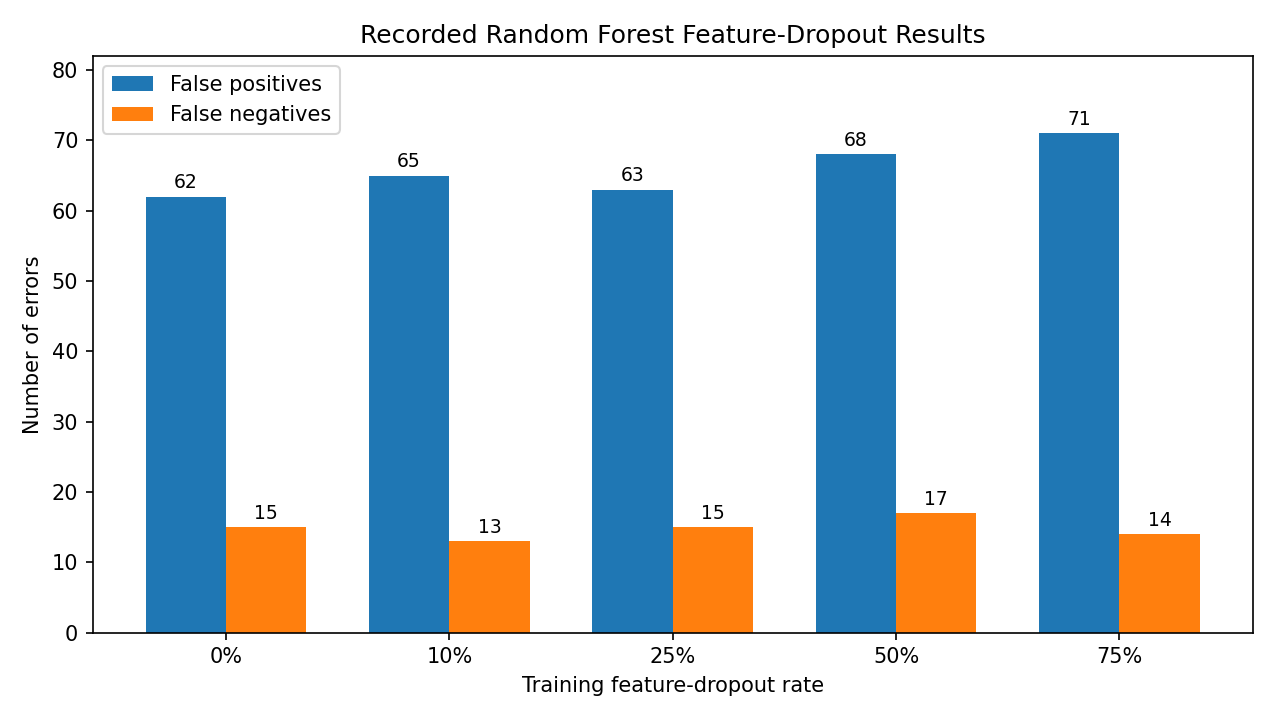

In [ ]:
# Visual comparison using the recorded feature-dropout results.
# The values below are taken from the original experiment, not newly fitted models.
import numpy as np
import matplotlib.pyplot as plt
rates = ["0%", "10%", "25%", "50%", "75%"]
fp_counts = [62, 65, 63, 68, 71]
fn_counts = [15, 13, 15, 17, 14]
x = np.arange(len(rates))
width = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4.8))
fp_bars = ax.bar(x - width / 2, fp_counts, width, label="False positives")
fn_bars = ax.bar(x + width / 2, fn_counts, width, label="False negatives")
ax.set_xticks(x, rates)
ax.set_ylabel("Number of errors")
ax.set_xlabel("Training feature-dropout rate")
ax.set_title("Recorded Random Forest Feature-Dropout Results")
ax.legend()
ax.bar_label(fp_bars, padding=2)
ax.bar_label(fn_bars, padding=2)
ax.set_ylim(0, 82)
plt.tight_layout()
plt.show()

**Figure 1. False-positive and false-negative counts across the original feature-dropout trials.** The figure displays the same counts reported in Table 2. None of the tested dropout rates achieved the required reduction in false positives without increasing false negatives.

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 12: SHAP-GUIDED TARGETED FEATURE-DROPOUT REGULARIZATION
# FINAL TRAINING EXPERIMENT
# =========================================================================================================
#
# PURPOSE
# -------
# Reduce the Random Forest's dependence on SHAP-identified
# false-positive-driving TF-IDF features DURING TRAINING.
#
#
# METHOD
# ------
# 1. Start from the validated SHAP explanations of the 62 baseline FPs.
#
# 2. Identify features that:
#
#       - physically occur in baseline FP emails
#       - do NOT physically occur in any of the 15 baseline FN emails
#       - have positive SHAP contribution when present in FP emails
#
# 3. Rank those features.
#
# 4. Retain the strongest SHAP-guided candidate features.
#
# 5. Apply TARGETED FEATURE DROPOUT to those features in the
#    TRAINING SET ONLY.
#
#    Example:
#
#       dropout = 0.25
#
#    means approximately 25% of the non-zero training occurrences
#    of the selected SHAP features are set to zero.
#
#    This makes those features less consistently available to the
#    Random Forest during learning.
#
# 6. Retrain the Random Forest using exactly the same baseline
#    hyperparameters.
#
# 7. Evaluate on the ORIGINAL UNMODIFIED test set.
#
#
# OFFICIAL BASELINE
# -----------------
#
# TP = 4686
# FP = 62
# FN = 15
# TN = 5953
#
#
# THESIS OBJECTIVE
# ----------------
#
#       FP < 62
#
# while:
#
#       FN <= 15
#
#
# IMPORTANT
# ---------
# - Test set is NEVER modified.
# - TF-IDF vocabulary is NEVER refitted.
# - Decision threshold remains 0.50.
# - Locked baseline remains unchanged.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import hashlib
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


print("=" * 135)
print("RANDOM FOREST STEP 12")
print("SHAP-GUIDED TARGETED FEATURE-DROPOUT REGULARIZATION")
print("=" * 135)


# =========================================================================================================
# 2. FIXED OFFICIAL ENVIRONMENT
# =========================================================================================================

BASELINE_TP_STEP12 = 4686
BASELINE_FP_STEP12 = 62
BASELINE_FN_STEP12 = 15
BASELINE_TN_STEP12 = 5953

EXPECTED_TRAIN_ROWS_STEP12 = 42861
EXPECTED_TEST_ROWS_STEP12 = 10716
EXPECTED_FEATURES_STEP12 = 10000

EXPECTED_FP_STEP12 = 62
EXPECTED_FN_STEP12 = 15

RANDOM_STATE_STEP12 = 42


EXPECTED_FP_SHAP_HASH_STEP12 = (
    "ee5ba1345052c2ee03503e3ff956519a420d643a3384d33be247a1c27d31f1f1"
)

EXPECTED_FN_SHAP_HASH_STEP12 = (
    "d2f5f7f19b96785f2e3b8be18e53637075885bf4081fce7a6601abc73d601134"
)


# =========================================================================================================
# 3. VERIFY REQUIRED OBJECTS
# =========================================================================================================

required_objects_step12 = [
    "X_train_tfidf",
    "X_test_tfidf",
    "y_train",
    "y_test",
    "tfidf_vectorizer",
    "rf_baseline_predictions_locked"
]


missing_objects_step12 = [
    obj
    for obj in required_objects_step12
    if obj not in globals()
]


if missing_objects_step12:

    raise RuntimeError(
        "\nRequired locked objects are missing:\n"
        f"{missing_objects_step12}\n\n"
        "Recover the official Random Forest baseline first."
    )


# =========================================================================================================
# 4. RESOLVE LOCKED RANDOM FOREST MODEL
# =========================================================================================================

if "rf_baseline_model_locked" in globals():

    rf_baseline_step12 = rf_baseline_model_locked

elif "rf_model" in globals():

    rf_baseline_step12 = rf_model

else:

    raise RuntimeError(
        "Locked Random Forest model was not found."
    )


print(
    "\nLocked Random Forest baseline verified."
)


# =========================================================================================================
# 5. VERIFY MATRICES
# =========================================================================================================

assert X_train_tfidf.shape == (
    EXPECTED_TRAIN_ROWS_STEP12,
    EXPECTED_FEATURES_STEP12
)


assert X_test_tfidf.shape == (
    EXPECTED_TEST_ROWS_STEP12,
    EXPECTED_FEATURES_STEP12
)


y_train_step12 = np.asarray(
    y_train
).astype(int).reshape(-1)


y_test_step12 = np.asarray(
    y_test
).astype(int).reshape(-1)


baseline_pred_step12 = np.asarray(
    rf_baseline_predictions_locked
).astype(int).reshape(-1)


# =========================================================================================================
# 6. VERIFY OFFICIAL BASELINE
# =========================================================================================================

baseline_cm_step12 = confusion_matrix(
    y_test_step12,
    baseline_pred_step12,
    labels=[0, 1]
)


expected_cm_step12 = np.array([
    [4686, 62],
    [15, 5953]
])


assert np.array_equal(
    baseline_cm_step12,
    expected_cm_step12
)


print(
    "\nOfficial baseline:"
)


print(
    baseline_cm_step12
)


print(
    "\nTP=4686 | FP=62 | FN=15 | TN=5953"
)


# =========================================================================================================
# 7. HASH HELPER
# =========================================================================================================

def sha256_array_step12(array):

    array = np.ascontiguousarray(
        np.asarray(array)
    )

    return hashlib.sha256(
        array.tobytes()
    ).hexdigest()


# =========================================================================================================
# 8. LOAD VALIDATED FP SHAP MATRIX
# =========================================================================================================

if "fp_shap_values_rf" in globals():

    fp_shap_step12 = np.asarray(
        fp_shap_values_rf,
        dtype=np.float64
    )

else:

    FP_SHAP_PATH_STEP12 = (
        str(RF04_OUTPUT_ROOT) + "/"
        "Random_Forest_SHAP_Guided_Phishing_Detection/"
        "Step8_Interventional_FP_SHAP/"
        "RF_FP_Interventional_SHAP.npy"
    )

    fp_shap_step12 = np.load(
        FP_SHAP_PATH_STEP12
    )


assert fp_shap_step12.shape == (
    62,
    10000
)


assert (
    sha256_array_step12(
        fp_shap_step12.astype(np.float64)
    )
    ==
    EXPECTED_FP_SHAP_HASH_STEP12
)


# =========================================================================================================
# 9. LOAD VALIDATED FN SHAP MATRIX
# =========================================================================================================

if "RF_FN_SHAP_VALUES" in globals():

    fn_shap_step12 = np.asarray(
        RF_FN_SHAP_VALUES,
        dtype=np.float64
    )

elif "fn_shap_values_step11" in globals():

    fn_shap_step12 = np.asarray(
        fn_shap_values_step11,
        dtype=np.float64
    )

else:

    FN_SHAP_PATH_STEP12 = (
        str(RF04_OUTPUT_ROOT) + "/"
        "Random_Forest_SHAP_Guided_Phishing_Detection/"
        "Step11_FN_SHAP/"
        "RF_FN_Interventional_SHAP.npy"
    )

    fn_shap_step12 = np.load(
        FN_SHAP_PATH_STEP12
    )


assert fn_shap_step12.shape == (
    15,
    10000
)


assert (
    sha256_array_step12(
        fn_shap_step12.astype(np.float64)
    )
    ==
    EXPECTED_FN_SHAP_HASH_STEP12
)


print(
    "\nValidated FP and FN SHAP matrices loaded successfully."
)


# =========================================================================================================
# 10. EXTRACT BASELINE FP AND FN POSITIONS
# =========================================================================================================

fp_positions_step12 = np.where(
    (y_test_step12 == 0)
    &
    (baseline_pred_step12 == 1)
)[0]


fn_positions_step12 = np.where(
    (y_test_step12 == 1)
    &
    (baseline_pred_step12 == 0)
)[0]


assert len(
    fp_positions_step12
) == 62


assert len(
    fn_positions_step12
) == 15


fp_tfidf_step12 = (
    X_test_tfidf[
        fp_positions_step12
    ]
    .tocsr()
)


fn_tfidf_step12 = (
    X_test_tfidf[
        fn_positions_step12
    ]
    .tocsr()
)


# =========================================================================================================
# 11. FEATURE NAMES
# =========================================================================================================

feature_names_step12 = np.asarray(
    tfidf_vectorizer.get_feature_names_out()
)


assert len(
    feature_names_step12
) == 10000


# =========================================================================================================
# 12. ACTUAL FEATURE PRESENCE IN FP AND FN
# =========================================================================================================

fp_presence_step12 = (
    fp_tfidf_step12 > 0
)


fn_presence_step12 = (
    fn_tfidf_step12 > 0
)


fp_presence_count_step12 = np.asarray(
    fp_presence_step12.sum(axis=0)
).reshape(-1)


fn_presence_count_step12 = np.asarray(
    fn_presence_step12.sum(axis=0)
).reshape(-1)


# =========================================================================================================
# 13. CALCULATE FP SHAP ONLY WHEN FEATURE IS ACTUALLY PRESENT
# =========================================================================================================

mean_present_fp_shap_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12
)


positive_present_count_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12,
    dtype=int
)


positive_present_percent_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12
)


positive_shap_mass_step12 = np.zeros(
    EXPECTED_FEATURES_STEP12
)


for j_step12 in range(
    EXPECTED_FEATURES_STEP12
):

    rows_step12 = (
        fp_presence_step12[
            :,
            j_step12
        ]
        .nonzero()[0]
    )


    if len(rows_step12) == 0:

        continue


    shap_values_present_step12 = (
        fp_shap_step12[
            rows_step12,
            j_step12
        ]
    )


    mean_present_fp_shap_step12[
        j_step12
    ] = np.mean(
        shap_values_present_step12
    )


    positive_present_count_step12[
        j_step12
    ] = int(
        np.sum(
            shap_values_present_step12 > 0
        )
    )


    positive_present_percent_step12[
        j_step12
    ] = (
        positive_present_count_step12[
            j_step12
        ]
        /
        len(rows_step12)
    ) * 100


    positive_shap_mass_step12[
        j_step12
    ] = np.sum(
        shap_values_present_step12[
            shap_values_present_step12 > 0
        ]
    )


# =========================================================================================================
# 14. BUILD SHAP-GUIDED FEATURE TABLE
# =========================================================================================================

feature_table_step12 = pd.DataFrame({

    "Feature":
        feature_names_step12,

    "FP_Presence_Count":
        fp_presence_count_step12,

    "FN_Presence_Count":
        fn_presence_count_step12,

    "Mean_FP_SHAP_When_Present":
        mean_present_fp_shap_step12,

    "Positive_FP_SHAP_Count":
        positive_present_count_step12,

    "Positive_FP_SHAP_Percent":
        positive_present_percent_step12,

    "Positive_SHAP_Mass":
        positive_shap_mass_step12
})


# =========================================================================================================
# 15. SELECT SHAP-GUIDED REGULARIZATION FEATURES
# =========================================================================================================
#
# Conditions:
#
# 1. Present in FP emails
# 2. Absent from all baseline FN emails
# 3. Positive mean SHAP when present
#
# =========================================================================================================

regularization_candidates_step12 = (

    feature_table_step12[

        (
            feature_table_step12[
                "FP_Presence_Count"
            ] > 0
        )

        &

        (
            feature_table_step12[
                "FN_Presence_Count"
            ] == 0
        )

        &

        (
            feature_table_step12[
                "Mean_FP_SHAP_When_Present"
            ] > 0
        )
    ]

    .copy()
)


regularization_candidates_step12 = (

    regularization_candidates_step12

    .sort_values(

        by=[
            "FP_Presence_Count",
            "Positive_SHAP_Mass",
            "Mean_FP_SHAP_When_Present"
        ],

        ascending=[
            False,
            False,
            False
        ]
    )

    .reset_index(drop=True)
)


# =========================================================================================================
# 16. RETAIN TOP SHAP-GUIDED FEATURES
# =========================================================================================================
#
# We use Top 20 for the regularization experiment.
#
# =========================================================================================================

TOP_N_FEATURES_STEP12 = 20


top_regularization_features_step12 = (

    regularization_candidates_step12
    .head(
        TOP_N_FEATURES_STEP12
    )
    .copy()
)


selected_features_step12 = (

    top_regularization_features_step12[
        "Feature"
    ]
    .tolist()
)


print(
    "\n" + "=" * 135
)

print(
    "SHAP-GUIDED REGULARIZATION FEATURES"
)

print(
    "=" * 135
)


display(
    top_regularization_features_step12
)


print(
    "\nSelected features:"
)


for rank_step12, feature_step12 in enumerate(
    selected_features_step12,
    start=1
):

    print(
        f"{rank_step12:02d}. {feature_step12}"
    )


# =========================================================================================================
# 17. FEATURE → INDEX MAP
# =========================================================================================================

feature_to_index_step12 = {
    feature: index
    for index, feature in enumerate(
        feature_names_step12
    )
}


selected_indices_step12 = [
    feature_to_index_step12[
        feature
    ]
    for feature in selected_features_step12
]


# =========================================================================================================
# 18. PRECOMPUTE DETERMINISTIC RANDOM NUMBERS FOR FEATURE DROPOUT
# =========================================================================================================
#
# This makes dropout levels nested and reproducible.
#
# Example:
#
# rate 0.25 removes a subset.
# rate 0.50 removes that same subset plus additional values.
#
# =========================================================================================================

rng_step12 = np.random.default_rng(
    RANDOM_STATE_STEP12
)


X_train_csc_reference_step12 = (
    X_train_tfidf
    .tocsc(
        copy=True
    )
)


dropout_random_values_step12 = {}


for feature_step12, index_step12 in zip(
    selected_features_step12,
    selected_indices_step12
):


    start_step12 = (
        X_train_csc_reference_step12.indptr[
            index_step12
        ]
    )


    end_step12 = (
        X_train_csc_reference_step12.indptr[
            index_step12 + 1
        ]
    )


    count_step12 = (
        end_step12
        -
        start_step12
    )


    dropout_random_values_step12[
        feature_step12
    ] = rng_step12.random(
        count_step12
    )


# =========================================================================================================
# 19. DROPOUT REGULARIZATION LEVELS
# =========================================================================================================
#
# 0.00 is the control.
#
# =========================================================================================================

dropout_rates_step12 = [
    0.00,
    0.10,
    0.25,
    0.50,
    0.75
]


print(
    "\nDropout regularization rates:"
)

print(
    dropout_rates_step12
)


# =========================================================================================================
# 20. RUN SHAP-GUIDED REGULARIZATION EXPERIMENT
# =========================================================================================================

results_step12 = []


for dropout_rate_step12 in dropout_rates_step12:


    print(
        "\n" + "-" * 135
    )


    print(
        f"TARGETED FEATURE DROPOUT = "
        f"{dropout_rate_step12:.0%}"
    )


    # -----------------------------------------------------------------------------------------------------
    # Create temporary TRAINING matrix only.
    # -----------------------------------------------------------------------------------------------------

    X_train_regularized_step12 = (
        X_train_tfidf
        .tocsc(
            copy=True
        )
    )


    total_nonzero_before_step12 = 0
    total_removed_step12 = 0


    # -----------------------------------------------------------------------------------------------------
    # Apply deterministic targeted dropout
    # -----------------------------------------------------------------------------------------------------

    if dropout_rate_step12 > 0:


        for feature_step12, index_step12 in zip(
            selected_features_step12,
            selected_indices_step12
        ):


            start_step12 = (
                X_train_regularized_step12.indptr[
                    index_step12
                ]
            )


            end_step12 = (
                X_train_regularized_step12.indptr[
                    index_step12 + 1
                ]
            )


            count_step12 = (
                end_step12
                -
                start_step12
            )


            total_nonzero_before_step12 += (
                count_step12
            )


            if count_step12 == 0:

                continue


            random_values_step12 = (
                dropout_random_values_step12[
                    feature_step12
                ]
            )


            remove_mask_step12 = (
                random_values_step12
                <
                dropout_rate_step12
            )


            data_slice_step12 = (
                X_train_regularized_step12.data[
                    start_step12:end_step12
                ]
            )


            data_slice_step12[
                remove_mask_step12
            ] = 0.0


            total_removed_step12 += int(
                np.sum(
                    remove_mask_step12
                )
            )


        X_train_regularized_step12.eliminate_zeros()


    else:


        for index_step12 in selected_indices_step12:


            start_step12 = (
                X_train_regularized_step12.indptr[
                    index_step12
                ]
            )


            end_step12 = (
                X_train_regularized_step12.indptr[
                    index_step12 + 1
                ]
            )


            total_nonzero_before_step12 += (
                end_step12
                -
                start_step12
            )


    X_train_regularized_step12 = (
        X_train_regularized_step12.tocsr()
    )


    print(
        "Selected-feature training occurrences:",
        total_nonzero_before_step12
    )


    print(
        "Occurrences dropped:",
        total_removed_step12
    )


    # =====================================================================================================
    # 21. TRAIN RANDOM FOREST
    # =====================================================================================================

    rf_regularized_step12 = RandomForestClassifier(

        n_estimators=100,

        criterion="gini",

        max_depth=None,

        min_samples_split=2,

        min_samples_leaf=1,

        max_features="sqrt",

        bootstrap=True,

        class_weight=None,

        ccp_alpha=0.0,

        n_jobs=-1,

        random_state=42
    )


    rf_regularized_step12.fit(

        X_train_regularized_step12,

        y_train_step12
    )


    # =====================================================================================================
    # 22. EVALUATE ON ORIGINAL UNMODIFIED TEST SET
    # =====================================================================================================

    pred_step12 = (
        rf_regularized_step12.predict(
            X_test_tfidf
        )
    )


    prob_step12 = (
        rf_regularized_step12.predict_proba(
            X_test_tfidf
        )[:, 1]
    )


    cm_step12 = confusion_matrix(
        y_test_step12,
        pred_step12,
        labels=[0, 1]
    )


    TP_step12 = int(
        cm_step12[0, 0]
    )


    FP_step12 = int(
        cm_step12[0, 1]
    )


    FN_step12 = int(
        cm_step12[1, 0]
    )


    TN_step12 = int(
        cm_step12[1, 1]
    )


    # =====================================================================================================
    # 23. METRICS
    # =====================================================================================================

    accuracy_step12 = accuracy_score(
        y_test_step12,
        pred_step12
    )


    precision_step12 = precision_score(
        y_test_step12,
        pred_step12,
        pos_label=1
    )


    recall_step12 = recall_score(
        y_test_step12,
        pred_step12,
        pos_label=1
    )


    f1_step12 = f1_score(
        y_test_step12,
        pred_step12,
        pos_label=1
    )


    auc_step12 = roc_auc_score(
        y_test_step12,
        prob_step12
    )


    # =====================================================================================================
    # 24. OBJECTIVE CHECK
    # =====================================================================================================

    FP_change_step12 = (
        FP_step12
        -
        BASELINE_FP_STEP12
    )


    FN_change_step12 = (
        FN_step12
        -
        BASELINE_FN_STEP12
    )


    FP_reduced_step12 = (
        FP_step12
        <
        BASELINE_FP_STEP12
    )


    FN_safe_step12 = (
        FN_step12
        <=
        BASELINE_FN_STEP12
    )


    objective_met_step12 = (
        FP_reduced_step12
        and
        FN_safe_step12
    )


    results_step12.append({

        "Dropout_Rate":
            dropout_rate_step12,

        "Selected_Features":
            len(
                selected_features_step12
            ),

        "Occurrences_Dropped":
            total_removed_step12,

        "TP":
            TP_step12,

        "FP":
            FP_step12,

        "FN":
            FN_step12,

        "TN":
            TN_step12,

        "FP_Change":
            FP_change_step12,

        "FN_Change":
            FN_change_step12,

        "Accuracy":
            accuracy_step12,

        "Precision":
            precision_step12,

        "Recall":
            recall_step12,

        "F1":
            f1_step12,

        "ROC_AUC":
            auc_step12,

        "FP_Reduced":
            FP_reduced_step12,

        "FN_Safe":
            FN_safe_step12,

        "Objective_Met":
            objective_met_step12
    })


    print(
        "\nConfusion matrix:"
    )

    print(
        cm_step12
    )


    print(
        "\nThesis Convention:"
    )


    print(
        f"TP={TP_step12} | "
        f"FP={FP_step12} | "
        f"FN={FN_step12} | "
        f"TN={TN_step12}"
    )


    print(
        "\nFP change:",
        f"{FP_change_step12:+d}"
    )


    print(
        "FN change:",
        f"{FN_change_step12:+d}"
    )


    print(
        "Objective met:",
        objective_met_step12
    )


# =========================================================================================================
# 25. RESULTS TABLE
# =========================================================================================================

regularization_results_step12 = pd.DataFrame(
    results_step12
)


print(
    "\n" + "=" * 135
)

print(
    "STEP 12 SHAP-GUIDED REGULARIZATION RESULTS"
)

print(
    "=" * 135
)


display(
    regularization_results_step12.style.format({

        "Dropout_Rate":
            "{:.0%}",

        "Accuracy":
            "{:.6f}",

        "Precision":
            "{:.6f}",

        "Recall":
            "{:.6f}",

        "F1":
            "{:.6f}",

        "ROC_AUC":
            "{:.6f}"
    })
)


# =========================================================================================================
# 26. SUCCESSFUL CONFIGURATIONS
# =========================================================================================================

successful_step12 = (

    regularization_results_step12[

        regularization_results_step12[
            "Objective_Met"
        ]
    ]

    .copy()
)


print(
    "\n" + "=" * 135
)

print(
    "SUCCESSFUL SHAP-GUIDED REGULARIZATION SETTINGS"
)

print(
    "=" * 135
)


if len(
    successful_step12
) == 0:


    print(
        "\nNo targeted dropout configuration achieved:"
    )

    print(
        "FP < 62 while FN <= 15."
    )


else:


    successful_step12 = (

        successful_step12

        .sort_values(
            by=[
                "FP",
                "FN",
                "F1",
                "Dropout_Rate"
            ],

            ascending=[
                True,
                True,
                False,
                True
            ]
        )

        .reset_index(drop=True)
    )


    display(
        successful_step12
    )


# =========================================================================================================
# 27. BEST RESULT
# =========================================================================================================

best_step12 = (

    regularization_results_step12

    .sort_values(
        by=[
            "FN_Safe",
            "FP",
            "FN",
            "F1"
        ],

        ascending=[
            False,
            True,
            True,
            False
        ]
    )

    .iloc[0]
)


print(
    "\n" + "=" * 135
)

print(
    "BEST STEP 12 RESULT"
)

print(
    "=" * 135
)


print(
    "\nDropout rate:",
    best_step12[
        "Dropout_Rate"
    ]
)


print(
    "FP:",
    int(
        best_step12["FP"]
    )
)


print(
    "FN:",
    int(
        best_step12["FN"]
    )
)


print(
    "FP change:",
    int(
        best_step12[
            "FP_Change"
        ]
    )
)


print(
    "FN change:",
    int(
        best_step12[
            "FN_Change"
        ]
    )
)


print(
    "Objective met:",
    bool(
        best_step12[
            "Objective_Met"
        ]
    )
)


# =========================================================================================================
# 28. SAVE RESULTS
# =========================================================================================================

STEP12_FOLDER = (
    str(RF04_OUTPUT_ROOT) + "/"
    "Random_Forest_SHAP_Guided_Phishing_Detection/"
    "Step12_SHAP_Guided_Regularization"
)


os.makedirs(
    STEP12_FOLDER,
    exist_ok=True
)


RESULTS_PATH_STEP12 = os.path.join(

    STEP12_FOLDER,

    "RF_SHAP_Guided_Targeted_Dropout_Regularization.csv"
)


FEATURES_PATH_STEP12 = os.path.join(

    STEP12_FOLDER,

    "RF_SHAP_Guided_Regularization_Features.csv"
)


regularization_results_step12.to_csv(
    RESULTS_PATH_STEP12,
    index=False
)


top_regularization_features_step12.to_csv(
    FEATURES_PATH_STEP12,
    index=False
)


# =========================================================================================================
# 29. VARIABLES FOR NEXT STEP
# =========================================================================================================

RF_STEP12_REGULARIZATION_RESULTS = (
    regularization_results_step12.copy()
)


RF_STEP12_SELECTED_FEATURES = (
    selected_features_step12.copy()
)


RF_STEP12_SUCCESSFUL_SETTINGS = (
    successful_step12.copy()
)


# =========================================================================================================
# 30. FINAL SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 135
)

print(
    "RANDOM FOREST STEP 12 COMPLETE"
)

print(
    "=" * 135
)


print(
    "\nOfficial baseline:"
)


print(
    "TP=4686 | FP=62 | FN=15 | TN=5953"
)


print(
    "\nRegularization method:"
)


print(
    "SHAP-guided targeted feature dropout during training"
)


print(
    "\nSelected SHAP features:",
    len(
        selected_features_step12
    )
)


print(
    "Dropout rates tested:",
    dropout_rates_step12
)


print(
    "\nOriginal test matrix was NOT modified."
)


print(
    "TF-IDF vocabulary was NOT refitted."
)


print(
    "Decision threshold remained 0.50."
)


print(
    "Official baseline remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "If SHAP-guided regularization does not achieve the "
    "FP/FN objective, proceed to counterfactual-guided "
    "training augmentation."
)

## 3. Counterfactual baseline and decision boundary

After the unsuccessful feature-dropout trials, the analysis returned to the official locked baseline. It verified the baseline model and its fixed test predictions, extracted the 62 false-positive cases, and measured their predicted phishing probabilities relative to the 0.50 decision reference.

The recorded false-positive probabilities ranged from **0.51 to 1.00**, with a mean of **0.72671661** and a median of **0.68530852**. Cases close to the decision boundary were of particular interest because smaller changes might reverse their predictions. No retraining occurred during this preparation.

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13A: COUNTERFACTUAL BASELINE & DECISION BOUNDARY
# =========================================================================================================
#
# PURPOSE
# -------
# Prepare the official locked Random Forest baseline for the
# counterfactual phase.
#
#
# STEP 13A WILL:
#
# 1. Verify the locked Random Forest model.
#
# 2. Verify the locked TF-IDF vectorizer.
#
# 3. Verify the fixed training/testing TF-IDF matrices.
#
# 4. Reproduce the official locked Random Forest predictions.
#
# 5. Confirm:
#
#       TP = 4686
#       FP = 62
#       FN = 15
#       TN = 5953
#
# 6. Extract exactly the 62 official false positives.
#
# 7. Compute each FP's Random Forest phishing probability.
#
# 8. Compute each FP's probability margin above the 0.50
#    class-probability reference boundary.
#
# 9. Count each FP's active TF-IDF features.
#
# 10. Rank all 62 FPs from closest to farthest from the
#     Random Forest probability boundary.
#
# 11. Save restart-safe counterfactual preparation files.
#
#
# IMPORTANT
# ---------
#
# - NO counterfactual is generated.
# - NO feature masking is performed.
# - NO synthetic email is generated.
# - NO retraining occurs.
# - NO augmentation occurs.
# - Locked Random Forest remains unchanged.
# - Locked TF-IDF vocabulary remains unchanged.
# - Original test matrix remains unchanged.
#
#
# THESIS CONVENTION
# -----------------
#
# TP = legitimate -> legitimate
# FP = legitimate -> phishing
# FN = phishing   -> legitimate
# TN = phishing   -> phishing
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix


print("=" * 135)
print("RANDOM FOREST STEP 13A")
print("COUNTERFACTUAL BASELINE & DECISION BOUNDARY")
print("=" * 135)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_TRAIN_13A = 42861
EXPECTED_TEST_13A = 10716
EXPECTED_FEATURES_13A = 10000

EXPECTED_TP_13A = 4686
EXPECTED_FP_13A = 62
EXPECTED_FN_13A = 15
EXPECTED_TN_13A = 5953

REFERENCE_BOUNDARY_13A = 0.50

PROJECT_ROOT_13A = (
    str(RF04_OUTPUT_ROOT) + "/"
    "Random_Forest_SHAP_Guided_Phishing_Detection"
)

STEP13A_FOLDER = os.path.join(
    PROJECT_ROOT_13A,
    "Step13A_Counterfactual_Baseline"
)

os.makedirs(
    STEP13A_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. RESOLVE LOCKED RANDOM FOREST MODEL
# =========================================================================================================

model_candidates_13a = [
    "rf_baseline_model_locked",
    "rf_model_locked",
    "rf_model"
]

rf_model_13a = None
rf_model_source_13a = None

for candidate_13a in model_candidates_13a:

    if candidate_13a in globals():

        candidate_model_13a = globals()[
            candidate_13a
        ]

        if (
            hasattr(candidate_model_13a, "predict")
            and
            hasattr(candidate_model_13a, "predict_proba")
            and
            hasattr(candidate_model_13a, "estimators_")
        ):

            rf_model_13a = candidate_model_13a
            rf_model_source_13a = candidate_13a

            break


if rf_model_13a is None:

    raise RuntimeError(
        "\nLocked Random Forest model was not found.\n"
        "Recover the official baseline first."
    )


print(
    "\nLocked Random Forest resolved from:",
    rf_model_source_13a
)

print(
    "Number of trees:",
    len(
        rf_model_13a.estimators_
    )
)

assert len(
    rf_model_13a.estimators_
) == 100


# =========================================================================================================
# 4. VERIFY OFFICIAL RANDOM FOREST PARAMETERS
# =========================================================================================================

rf_params_13a = (
    rf_model_13a.get_params()
)

expected_params_13a = {

    "n_estimators": 100,
    "criterion": "gini",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "bootstrap": True,
    "class_weight": None,
    "ccp_alpha": 0.0,
    "random_state": 42
}

for parameter_13a, expected_value_13a in expected_params_13a.items():

    actual_value_13a = rf_params_13a[
        parameter_13a
    ]

    assert (
        actual_value_13a
        ==
        expected_value_13a
    ), (
        f"Parameter mismatch: {parameter_13a}\n"
        f"Expected: {expected_value_13a}\n"
        f"Found: {actual_value_13a}"
    )


print(
    "\nLocked Random Forest parameters verified."
)


# =========================================================================================================
# 5. RESOLVE LOCKED TF-IDF VECTORIZER
# =========================================================================================================

vectorizer_candidates_13a = [
    "tfidf_vectorizer",
    "tfidf_vectorizer_locked"
]

tfidf_vectorizer_13a = None
vectorizer_source_13a = None

for candidate_13a in vectorizer_candidates_13a:

    if candidate_13a in globals():

        tfidf_vectorizer_13a = globals()[
            candidate_13a
        ]

        vectorizer_source_13a = candidate_13a

        break


if tfidf_vectorizer_13a is None:

    raise RuntimeError(
        "Locked TF-IDF vectorizer was not found."
    )


print(
    "Locked TF-IDF vectorizer resolved from:",
    vectorizer_source_13a
)


# =========================================================================================================
# 6. VERIFY REQUIRED LOCKED OBJECTS
# =========================================================================================================

required_objects_13a = [
    "X_train_tfidf",
    "X_test_tfidf",
    "y_train",
    "y_test",
    "rf_baseline_predictions_locked"
]

missing_objects_13a = [
    object_name_13a
    for object_name_13a in required_objects_13a
    if object_name_13a not in globals()
]

if missing_objects_13a:

    raise RuntimeError(
        "\nMissing required locked objects:\n"
        f"{missing_objects_13a}"
    )


# =========================================================================================================
# 7. VERIFY DATA DIMENSIONS
# =========================================================================================================

assert X_train_tfidf.shape == (
    EXPECTED_TRAIN_13A,
    EXPECTED_FEATURES_13A
)

assert X_test_tfidf.shape == (
    EXPECTED_TEST_13A,
    EXPECTED_FEATURES_13A
)

assert len(
    y_train
) == EXPECTED_TRAIN_13A

assert len(
    y_test
) == EXPECTED_TEST_13A


feature_names_13a = np.asarray(
    tfidf_vectorizer_13a
    .get_feature_names_out()
)

assert len(
    feature_names_13a
) == EXPECTED_FEATURES_13A


print(
    "\nLocked data dimensions verified."
)

print(
    "Training matrix :",
    X_train_tfidf.shape
)

print(
    "Testing matrix  :",
    X_test_tfidf.shape
)

print(
    "TF-IDF features :",
    len(
        feature_names_13a
    )
)


# =========================================================================================================
# 8. PREPARE TEST LABELS
# =========================================================================================================

y_test_array_13a = (
    np.asarray(
        y_test
    )
    .astype(int)
    .reshape(-1)
)


# =========================================================================================================
# 9. REPRODUCE OFFICIAL RANDOM FOREST PREDICTIONS
# =========================================================================================================

current_predictions_13a = (
    np.asarray(
        rf_model_13a.predict(
            X_test_tfidf
        )
    )
    .astype(int)
    .reshape(-1)
)


locked_predictions_13a = (
    np.asarray(
        rf_baseline_predictions_locked
    )
    .astype(int)
    .reshape(-1)
)


assert np.array_equal(
    current_predictions_13a,
    locked_predictions_13a
), (
    "Current Random Forest does not reproduce "
    "the locked baseline predictions."
)


print(
    "\nOfficial locked predictions reproduced exactly."
)


# =========================================================================================================
# 10. VERIFY OFFICIAL CONFUSION MATRIX
# =========================================================================================================

baseline_cm_13a = confusion_matrix(
    y_test_array_13a,
    current_predictions_13a,
    labels=[0, 1]
)


TP_13A = int(
    baseline_cm_13a[0, 0]
)

FP_13A = int(
    baseline_cm_13a[0, 1]
)

FN_13A = int(
    baseline_cm_13a[1, 0]
)

TN_13A = int(
    baseline_cm_13a[1, 1]
)


assert TP_13A == EXPECTED_TP_13A
assert FP_13A == EXPECTED_FP_13A
assert FN_13A == EXPECTED_FN_13A
assert TN_13A == EXPECTED_TN_13A


print(
    "\nOfficial locked baseline verified:"
)

print(
    baseline_cm_13a
)

print(
    "\nTP=4686 | FP=62 | FN=15 | TN=5953"
)


# =========================================================================================================
# 11. RESOLVE CLASS-1 PROBABILITY COLUMN
# =========================================================================================================

classes_13a = np.asarray(
    rf_model_13a.classes_
)

class1_positions_13a = np.where(
    classes_13a == 1
)[0]

assert len(
    class1_positions_13a
) == 1

class1_column_13a = int(
    class1_positions_13a[0]
)


# =========================================================================================================
# 12. COMPUTE RANDOM FOREST PHISHING PROBABILITIES
# =========================================================================================================

probability_matrix_13a = (
    rf_model_13a.predict_proba(
        X_test_tfidf
    )
)

assert probability_matrix_13a.shape == (
    EXPECTED_TEST_13A,
    2
)


phishing_probabilities_13a = (
    probability_matrix_13a[
        :,
        class1_column_13a
    ]
)


assert np.all(
    phishing_probabilities_13a >= 0
)

assert np.all(
    phishing_probabilities_13a <= 1
)


# =========================================================================================================
# 13. EXTRACT EXACT OFFICIAL FALSE POSITIVES
# =========================================================================================================

fp_mask_13a = (

    (y_test_array_13a == 0)

    &

    (current_predictions_13a == 1)
)


fp_positions_13a = np.where(
    fp_mask_13a
)[0]


assert len(
    fp_positions_13a
) == EXPECTED_FP_13A


X_fp_tfidf_13a = (
    X_test_tfidf[
        fp_positions_13a
    ]
    .tocsr()
)


assert X_fp_tfidf_13a.shape == (
    EXPECTED_FP_13A,
    EXPECTED_FEATURES_13A
)


fp_probabilities_13a = (
    phishing_probabilities_13a[
        fp_positions_13a
    ]
)


print(
    "\nOfficial false positives extracted:",
    len(
        fp_positions_13a
    )
)

print(
    "FP TF-IDF matrix:",
    X_fp_tfidf_13a.shape
)


# =========================================================================================================
# 14. FP PROBABILITY STATISTICS
# =========================================================================================================

print(
    "\nFP phishing probability statistics:"
)

print(
    "Minimum:",
    float(
        np.min(
            fp_probabilities_13a
        )
    )
)

print(
    "Maximum:",
    float(
        np.max(
            fp_probabilities_13a
        )
    )
)

print(
    "Mean:",
    float(
        np.mean(
            fp_probabilities_13a
        )
    )
)

print(
    "Median:",
    float(
        np.median(
            fp_probabilities_13a
        )
    )
)


# =========================================================================================================
# 15. COMPUTE PROBABILITY MARGIN ABOVE 0.50
# =========================================================================================================
#
# IMPORTANT:
#
# This is NOT treated as an exact counterfactual distance.
#
# Random Forest is nonlinear.
#
# It is only used to rank the official FPs according to
# how close their current phishing probability is to 0.50.
#
# =========================================================================================================

fp_probability_margin_13a = (
    fp_probabilities_13a
    -
    REFERENCE_BOUNDARY_13A
)


print(
    "\nFP probability margin above 0.50:"
)

print(
    "Minimum:",
    float(
        np.min(
            fp_probability_margin_13a
        )
    )
)

print(
    "Maximum:",
    float(
        np.max(
            fp_probability_margin_13a
        )
    )
)

print(
    "Mean:",
    float(
        np.mean(
            fp_probability_margin_13a
        )
    )
)


# =========================================================================================================
# 16. COUNT ACTIVE TF-IDF FEATURES PER FP
# =========================================================================================================

fp_active_feature_counts_13a = np.asarray(

    (
        X_fp_tfidf_13a
        >
        0
    )

    .sum(
        axis=1
    )

).reshape(-1)


print(
    "\nActive TF-IDF feature count per FP:"
)

print(
    "Minimum:",
    int(
        np.min(
            fp_active_feature_counts_13a
        )
    )
)

print(
    "Maximum:",
    int(
        np.max(
            fp_active_feature_counts_13a
        )
    )
)

print(
    "Mean:",
    float(
        np.mean(
            fp_active_feature_counts_13a
        )
    )
)


# =========================================================================================================
# 17. OPTIONAL RAW FP EMAIL TEXT
# =========================================================================================================

raw_text_available_13a = False

if "X_test" in globals():

    try:

        X_test_reset_13a = (
            X_test.reset_index(
                drop=True
            )
        )

        fp_email_texts_13a = (

            X_test_reset_13a

            .iloc[
                fp_positions_13a
            ]

            .astype(str)

            .to_numpy()
        )

        raw_text_available_13a = True

    except Exception:

        fp_email_texts_13a = np.array(
            [""] * EXPECTED_FP_13A
        )

else:

    fp_email_texts_13a = np.array(
        [""] * EXPECTED_FP_13A
    )


print(
    "\nRaw FP email text available:",
    raw_text_available_13a
)


# =========================================================================================================
# 18. BUILD OFFICIAL FP COUNTERFACTUAL BASELINE TABLE
# =========================================================================================================

counterfactual_fp_baseline_13a = pd.DataFrame({

    "FP_Number":
        np.arange(
            1,
            EXPECTED_FP_13A + 1
        ),

    "Test_Position":
        fp_positions_13a,

    "True_Label":
        y_test_array_13a[
            fp_positions_13a
        ],

    "Official_RF_Prediction":
        current_predictions_13a[
            fp_positions_13a
        ],

    "Phishing_Probability":
        fp_probabilities_13a,

    "Probability_Margin_Above_0_50":
        fp_probability_margin_13a,

    "Active_TFIDF_Features":
        fp_active_feature_counts_13a,

    "Email_Text":
        fp_email_texts_13a
})


# =========================================================================================================
# 19. RANK 62 FPS BY BOUNDARY PROXIMITY
# =========================================================================================================

counterfactual_fp_ranked_13a = (

    counterfactual_fp_baseline_13a

    .sort_values(
        by=[
            "Phishing_Probability",
            "FP_Number"
        ],
        ascending=[
            True,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


counterfactual_fp_ranked_13a.insert(
    0,
    "Boundary_Rank",
    np.arange(
        1,
        EXPECTED_FP_13A + 1
    )
)


print(
    "\nTop 10 official FPs closest to the probability boundary:"
)


display(

    counterfactual_fp_ranked_13a[
        [
            "Boundary_Rank",
            "FP_Number",
            "Test_Position",
            "Phishing_Probability",
            "Probability_Margin_Above_0_50",
            "Active_TFIDF_Features"
        ]
    ]

    .head(10)

    .style.format({

        "Phishing_Probability":
            "{:.8f}",

        "Probability_Margin_Above_0_50":
            "{:+.8f}"
    })
)


# =========================================================================================================
# 20. SAVE OFFICIAL FP BASELINE TABLE
# =========================================================================================================

FP_BASELINE_PATH_13A = os.path.join(

    STEP13A_FOLDER,

    "Step13A_RF_Official_62_FP_Counterfactual_Baseline.csv"
)


counterfactual_fp_baseline_13a.to_csv(
    FP_BASELINE_PATH_13A,
    index=False
)


# =========================================================================================================
# 21. SAVE BOUNDARY RANKING TABLE
# =========================================================================================================

FP_RANK_PATH_13A = os.path.join(

    STEP13A_FOLDER,

    "Step13A_RF_Official_62_FP_Boundary_Ranking.csv"
)


counterfactual_fp_ranked_13a.to_csv(
    FP_RANK_PATH_13A,
    index=False
)


# =========================================================================================================
# 22. HASH BASELINE TABLE
# =========================================================================================================

def sha256_file_13a(path_13a):

    sha_13a = hashlib.sha256()

    with open(
        path_13a,
        "rb"
    ) as file_13a:

        for block_13a in iter(

            lambda:
                file_13a.read(
                    1024 * 1024
                ),

            b""
        ):

            sha_13a.update(
                block_13a
            )

    return sha_13a.hexdigest()


fp_baseline_hash_13a = (
    sha256_file_13a(
        FP_BASELINE_PATH_13A
    )
)


print(
    "\nStep 13A FP baseline SHA-256:"
)

print(
    fp_baseline_hash_13a
)


# =========================================================================================================
# 23. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13A = os.path.join(

    STEP13A_FOLDER,

    "Step13A_Config.json"
)


config_13a = {

    "step":
        "13A",

    "method":
        (
            "Random Forest counterfactual baseline "
            "and probability-boundary preparation"
        ),

    "baseline": {

        "TP":
            TP_13A,

        "FP":
            FP_13A,

        "FN":
            FN_13A,

        "TN":
            TN_13A
    },

    "reference_boundary":
        REFERENCE_BOUNDARY_13A,

    "authoritative_prediction":
        "RandomForestClassifier.predict",

    "false_positives_prepared":
        EXPECTED_FP_13A,

    "train_samples":
        EXPECTED_TRAIN_13A,

    "test_samples":
        EXPECTED_TEST_13A,

    "tfidf_features":
        EXPECTED_FEATURES_13A,

    "raw_text_available":
        bool(
            raw_text_available_13a
        ),

    "counterfactual_generated":
        False,

    "counterfactual_aggregation":
        False,

    "text_reconstruction":
        False,

    "synthetic_email_generated":
        False,

    "synthetic_validation":
        False,

    "training_augmentation":
        False,

    "model_retrained":
        False,

    "test_matrix_modified":
        False,

    "tfidf_refitted":
        False
}


with open(

    CONFIG_PATH_13A,

    "w"

) as file_13a:

    json.dump(
        config_13a,
        file_13a,
        indent=4
    )


# =========================================================================================================
# 24. CONVENIENT OBJECTS FOR STEP 13B
# =========================================================================================================

RF_STEP13A_FP_POSITIONS = (
    fp_positions_13a.copy()
)


RF_STEP13A_FP_MATRIX = (
    X_fp_tfidf_13a.copy()
)


RF_STEP13A_FP_PROBABILITIES = (
    fp_probabilities_13a.copy()
)


RF_STEP13A_FP_BASELINE = (
    counterfactual_fp_baseline_13a.copy()
)


RF_STEP13A_FP_BOUNDARY_RANKING = (
    counterfactual_fp_ranked_13a.copy()
)


RF_STEP13A_FEATURE_NAMES = (
    feature_names_13a.copy()
)


RF_STEP13A_BASELINE_HASH = (
    fp_baseline_hash_13a
)


# =========================================================================================================
# 25. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 135
)


print(
    "RANDOM FOREST STEP 13A COMPLETE"
)


print(
    "=" * 135
)


print(
    "\nOfficial baseline:"
)


print(
    "TP=4686 | FP=62 | FN=15 | TN=5953"
)


print(
    "\nOfficial false positives prepared:",
    EXPECTED_FP_13A
)


print(
    "Reference probability boundary:",
    REFERENCE_BOUNDARY_13A
)


print(
    "FP baseline hash:",
    fp_baseline_hash_13a
)


print(
    "\nNo counterfactual generated."
)


print(
    "No feature masking performed."
)


print(
    "No counterfactual aggregation performed."
)


print(
    "No text reconstruction performed."
)


print(
    "No synthetic email generated."
)


print(
    "No synthetic validation performed."
)


print(
    "No training augmentation performed."
)


print(
    "No retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "Original test matrix remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13B will discover minimal Random Forest "
    "counterfactual feature changes for all 62 official "
    "baseline false positives using direct locked-model "
    "re-evaluation."
)

## 4. Minimal counterfactual discovery

For each of the 62 false-positive emails, the original code ranked active features with positive SHAP contributions and progressively removed their TF-IDF values. A case was considered successful only when the locked Random Forest changed its prediction from phishing to legitimate. A further check attempted to remove unnecessary changes from each successful feature set.

The search identified **9 verified counterfactual cases out of 62 (14.52%)**. The remaining 53 cases did not change class under the tested search procedure. The resulting feature sets are **subset-minimal within this search**, not proven globally minimal.

**Table 3. Verified feature-space counterfactual cases**

| False-positive case | Test position | Original phishing probability | Counterfactual probability | Final features changed |
|---|---:|---:|---:|---:|
| FP 21 | 3304 | 0.590000 | 0.500000 | 5 |
| FP 23 | 3745 | 0.590000 | 0.500000 | 8 |
| FP 25 | 4322 | 0.530000 | 0.500000 | 1 |
| FP 26 | 4522 | 0.650000 | 0.500000 | 10 |
| FP 30 | 5016 | 0.510000 | 0.500000 | 1 |
| FP 38 | 5755 | 0.550000 | 0.500000 | 3 |
| FP 46 | 8056 | 0.529756 | 0.499518 | 3 |
| FP 58 | 9766 | 0.540000 | 0.500000 | 1 |
| FP 61 | 10552 | 0.650000 | 0.500000 | 9 |

*The table summarizes the verified final feature sets. The original code below produces the complete search history, case-specific features, and minimality checks.*

**Interpretation.** These counterfactuals operate on TF-IDF feature values, not directly on email text. A probability displayed as 0.500000 is not by itself evidence of a class change; the original procedure checked the model's predicted class explicitly.

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13B: MINIMAL COUNTERFACTUAL DISCOVERY
# ALL 62 OFFICIAL FALSE POSITIVES
# =========================================================================================================
#
# PURPOSE
# -------
# Discover SHAP-guided feature-level counterfactuals for ALL
# 62 official Random Forest false positives.
#
#
# STEP 13B WILL:
#
# 1. Recover the locked Random Forest.
#
# 2. Recover the official 62 FP cases prepared in Step 13A.
#
# 3. Load the validated FP SHAP matrix.
#
# 4. For EACH FP:
#
#       a. identify TF-IDF features physically active in that FP
#
#       b. retrieve SHAP values for those active features
#
#       c. retain only active features with SHAP > 0
#          because they push the FP toward Phishing
#
#       d. rank those features from strongest to weakest SHAP
#
#       e. progressively mask:
#
#              Top 1
#              Top 2
#              Top 3
#              ...
#
#          and DIRECTLY ask the locked Random Forest:
#
#              rf_model.predict(...)
#
#       f. stop when prediction changes:
#
#              Phishing (1) -> Legitimate (0)
#
#       g. prune unnecessary masked features
#
#       h. verify subset-minimality:
#
#          restoring any one final feature should return
#          the prediction to Phishing
#
#
# 5. Save:
#
#       - one summary row for each of the 62 FPs
#       - all successful counterfactual feature sets
#       - all failed cases
#       - feature-level counterfactual records
#
#
# IMPORTANT
# ---------
#
# - NO synthetic email is generated.
# - NO text reconstruction occurs.
# - NO training augmentation occurs.
# - NO retraining occurs.
# - Locked Random Forest remains unchanged.
# - Original test matrix remains unchanged.
#
#
# NOTE ON "MINIMAL"
# -----------------
#
# This step discovers a SUBSET-MINIMAL counterfactual within
# the SHAP-guided greedy search path.
#
# It does NOT claim globally optimal mathematical minimality
# across every possible combination of 10,000 TF-IDF features.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import json
import hashlib
import numpy as np
import pandas as pd


print("=" * 140)
print("RANDOM FOREST STEP 13B")
print("MINIMAL COUNTERFACTUAL DISCOVERY")
print("ALL 62 OFFICIAL FALSE POSITIVES")
print("=" * 140)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_FP_13B = 62
EXPECTED_FEATURES_13B = 10000

EXPECTED_FP_SHAP_HASH_13B = (
    "ee5ba1345052c2ee03503e3ff956519a420d643a3384d33be247a1c27d31f1f1"
)

# Maximum number of active positive-SHAP features explored per FP.
# Most FPs will have far fewer than this.
MAX_SEARCH_FEATURES_13B = 150


PROJECT_ROOT_13B = (
    str(RF04_OUTPUT_ROOT) + "/"
    "Random_Forest_SHAP_Guided_Phishing_Detection"
)


STEP13B_FOLDER = os.path.join(
    PROJECT_ROOT_13B,
    "Step13B_Minimal_Counterfactual_Discovery"
)


os.makedirs(
    STEP13B_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. HASH HELPER
# =========================================================================================================

def sha256_array_13b(array):

    array = np.ascontiguousarray(
        np.asarray(array)
    )

    return hashlib.sha256(
        array.tobytes()
    ).hexdigest()


# =========================================================================================================
# 4. VERIFY REQUIRED STEP 13A OBJECTS
# =========================================================================================================

required_step13a_objects_13b = [

    "RF_STEP13A_FP_POSITIONS",

    "RF_STEP13A_FP_MATRIX",

    "RF_STEP13A_FP_PROBABILITIES",

    "RF_STEP13A_FP_BASELINE",

    "RF_STEP13A_FP_BOUNDARY_RANKING",

    "RF_STEP13A_FEATURE_NAMES"
]


missing_step13a_objects_13b = [

    object_name_13b

    for object_name_13b
    in required_step13a_objects_13b

    if object_name_13b not in globals()
]


if missing_step13a_objects_13b:

    raise RuntimeError(

        "\nRequired Step 13A objects are missing:\n"

        f"{missing_step13a_objects_13b}\n\n"

        "Run Random Forest Step 13A first."
    )


# =========================================================================================================
# 5. RESOLVE LOCKED RANDOM FOREST
# =========================================================================================================

model_candidates_13b = [

    "rf_baseline_model_locked",

    "rf_model_locked",

    "rf_model"
]


rf_model_13b = None
rf_model_source_13b = None


for candidate_13b in model_candidates_13b:

    if candidate_13b in globals():

        model_13b = globals()[
            candidate_13b
        ]

        if (
            hasattr(model_13b, "predict")
            and
            hasattr(model_13b, "predict_proba")
            and
            hasattr(model_13b, "estimators_")
        ):

            rf_model_13b = model_13b

            rf_model_source_13b = candidate_13b

            break


if rf_model_13b is None:

    raise RuntimeError(
        "Locked Random Forest model was not found."
    )


print(
    "\nLocked Random Forest resolved from:",
    rf_model_source_13b
)


print(
    "Number of trees:",
    len(
        rf_model_13b.estimators_
    )
)


assert len(
    rf_model_13b.estimators_
) == 100


# =========================================================================================================
# 6. RESOLVE CLASS-1 PROBABILITY COLUMN
# =========================================================================================================

classes_13b = np.asarray(
    rf_model_13b.classes_
)


class1_positions_13b = np.where(
    classes_13b == 1
)[0]


assert len(
    class1_positions_13b
) == 1


class1_column_13b = int(
    class1_positions_13b[0]
)


# =========================================================================================================
# 7. VERIFY STEP 13A FP MATRICES
# =========================================================================================================

fp_positions_13b = np.asarray(
    RF_STEP13A_FP_POSITIONS
).astype(int)


X_fp_13b = (
    RF_STEP13A_FP_MATRIX
    .tocsr()
)


fp_probabilities_13b = np.asarray(
    RF_STEP13A_FP_PROBABILITIES,
    dtype=float
)


feature_names_13b = np.asarray(
    RF_STEP13A_FEATURE_NAMES
)


assert len(
    fp_positions_13b
) == EXPECTED_FP_13B


assert X_fp_13b.shape == (
    EXPECTED_FP_13B,
    EXPECTED_FEATURES_13B
)


assert fp_probabilities_13b.shape == (
    EXPECTED_FP_13B,
)


assert len(
    feature_names_13b
) == EXPECTED_FEATURES_13B


print(
    "\nStep 13A FP environment verified."
)


print(
    "Official FP cases:",
    len(
        fp_positions_13b
    )
)


print(
    "FP matrix:",
    X_fp_13b.shape
)


# =========================================================================================================
# 8. LOAD VALIDATED FP SHAP MATRIX
# =========================================================================================================

if "fp_shap_values_rf" in globals():

    fp_shap_13b = np.asarray(
        fp_shap_values_rf,
        dtype=np.float64
    )


else:

    FP_SHAP_PATH_13B = (
        str(RF04_OUTPUT_ROOT) + "/"
        "Random_Forest_SHAP_Guided_Phishing_Detection/"
        "Step8_Interventional_FP_SHAP/"
        "RF_FP_Interventional_SHAP.npy"
    )


    if not os.path.exists(
        FP_SHAP_PATH_13B
    ):

        raise RuntimeError(
            "Validated FP SHAP matrix was not found."
        )


    fp_shap_13b = np.load(
        FP_SHAP_PATH_13B
    )


assert fp_shap_13b.shape == (
    EXPECTED_FP_13B,
    EXPECTED_FEATURES_13B
)


fp_shap_hash_13b = sha256_array_13b(
    fp_shap_13b.astype(
        np.float64
    )
)


assert (
    fp_shap_hash_13b
    ==
    EXPECTED_FP_SHAP_HASH_13B
), (
    "FP SHAP hash verification failed."
)


print(
    "\nValidated FP SHAP matrix verified."
)


print(
    "FP SHAP matrix:",
    fp_shap_13b.shape
)


print(
    "FP SHAP SHA-256:",
    fp_shap_hash_13b
)


# =========================================================================================================
# 9. HELPER: MASK FEATURES IN ONE FP VECTOR
# =========================================================================================================

def mask_features_13b(
    original_vector_13b,
    feature_indices_13b
):


    modified_13b = (

        original_vector_13b

        .tocsc(
            copy=True
        )
    )


    for feature_index_13b in feature_indices_13b:


        start_13b = (
            modified_13b.indptr[
                feature_index_13b
            ]
        )


        end_13b = (
            modified_13b.indptr[
                feature_index_13b + 1
            ]
        )


        if end_13b > start_13b:

            modified_13b.data[
                start_13b:end_13b
            ] = 0.0


    modified_13b.eliminate_zeros()


    return modified_13b.tocsr()


# =========================================================================================================
# 10. HELPER: DIRECT RANDOM FOREST EVALUATION
# =========================================================================================================

def evaluate_vector_13b(
    vector_13b
):


    prediction_13b = int(

        rf_model_13b.predict(
            vector_13b
        )[0]
    )


    probability_13b = float(

        rf_model_13b.predict_proba(
            vector_13b
        )[
            0,
            class1_column_13b
        ]
    )


    return (
        prediction_13b,
        probability_13b
    )


# =========================================================================================================
# 11. RESULT CONTAINERS
# =========================================================================================================

summary_records_13b = []

feature_records_13b = []

progressive_records_13b = []

minimality_records_13b = []


# =========================================================================================================
# 12. PROCESS ALL 62 FALSE POSITIVES
# =========================================================================================================

for fp_row_13b in range(
    EXPECTED_FP_13B
):


    FP_NUMBER_13B = (
        fp_row_13b + 1
    )


    TEST_POSITION_13B = int(
        fp_positions_13b[
            fp_row_13b
        ]
    )


    original_vector_13b = (

        X_fp_13b[
            fp_row_13b
        ]

        .tocsr()
    )


    original_prediction_13b, (
        original_probability_13b
    ) = (

        evaluate_vector_13b(
            original_vector_13b
        )
    )


    assert original_prediction_13b == 1


    # -----------------------------------------------------------------------------------------------------
    # Active TF-IDF features
    # -----------------------------------------------------------------------------------------------------

    active_indices_13b = (
        original_vector_13b.indices
    )


    active_values_13b = (
        original_vector_13b.data
    )


    fp_shap_row_13b = (

        fp_shap_13b[
            fp_row_13b
        ]
    )


    active_shap_13b = (

        fp_shap_row_13b[
            active_indices_13b
        ]
    )


    # -----------------------------------------------------------------------------------------------------
    # Retain only active positive-SHAP features
    # -----------------------------------------------------------------------------------------------------

    positive_mask_13b = (
        active_shap_13b > 0
    )


    positive_indices_13b = (

        active_indices_13b[
            positive_mask_13b
        ]
    )


    positive_values_13b = (

        active_values_13b[
            positive_mask_13b
        ]
    )


    positive_shap_values_13b = (

        active_shap_13b[
            positive_mask_13b
        ]
    )


    # -----------------------------------------------------------------------------------------------------
    # No active positive-SHAP features
    # -----------------------------------------------------------------------------------------------------

    if len(
        positive_indices_13b
    ) == 0:


        summary_records_13b.append({

            "FP_Number":
                FP_NUMBER_13B,

            "Test_Position":
                TEST_POSITION_13B,

            "Original_Phishing_Probability":
                original_probability_13b,

            "Active_Features":
                len(
                    active_indices_13b
                ),

            "Active_Positive_SHAP_Features":
                0,

            "Counterfactual_Found":
                False,

            "Initial_Features_Masked":
                0,

            "Minimal_Features_Masked":
                0,

            "Counterfactual_Probability":
                np.nan,

            "Probability_Reduction":
                np.nan,

            "Subset_Minimal_Verified":
                False,

            "Counterfactual_Features":
                ""
        })


        print(
            f"FP {FP_NUMBER_13B:02d}/62 | "
            f"p={original_probability_13b:.6f} | "
            "NO active positive-SHAP features"
        )


        continue


    # -----------------------------------------------------------------------------------------------------
    # Sort active positive-SHAP features strongest first
    # -----------------------------------------------------------------------------------------------------

    order_13b = np.argsort(
        -positive_shap_values_13b
    )


    positive_indices_13b = (

        positive_indices_13b[
            order_13b
        ]
    )


    positive_values_13b = (

        positive_values_13b[
            order_13b
        ]
    )


    positive_shap_values_13b = (

        positive_shap_values_13b[
            order_13b
        ]
    )


    # -----------------------------------------------------------------------------------------------------
    # Save ranked positive feature records
    # -----------------------------------------------------------------------------------------------------

    for rank_position_13b in range(
        len(
            positive_indices_13b
        )
    ):


        idx_13b = int(
            positive_indices_13b[
                rank_position_13b
            ]
        )


        feature_records_13b.append({

            "FP_Number":
                FP_NUMBER_13B,

            "Test_Position":
                TEST_POSITION_13B,

            "Positive_SHAP_Rank":
                rank_position_13b + 1,

            "Feature_Index":
                idx_13b,

            "Feature":
                feature_names_13b[
                    idx_13b
                ],

            "TFIDF_Value":
                float(
                    positive_values_13b[
                        rank_position_13b
                    ]
                ),

            "SHAP_Value":
                float(
                    positive_shap_values_13b[
                        rank_position_13b
                    ]
                )
        })


    # -----------------------------------------------------------------------------------------------------
    # Progressive counterfactual search
    # -----------------------------------------------------------------------------------------------------

    search_limit_13b = min(

        MAX_SEARCH_FEATURES_13B,

        len(
            positive_indices_13b
        )
    )


    first_successful_indices_13b = None


    for number_masked_13b in range(
        1,
        search_limit_13b + 1
    ):


        current_indices_13b = (

            positive_indices_13b[
                :number_masked_13b
            ]

            .astype(int)

            .tolist()
        )


        modified_vector_13b = (

            mask_features_13b(

                original_vector_13b,

                current_indices_13b
            )
        )


        new_prediction_13b, (
            new_probability_13b
        ) = (

            evaluate_vector_13b(
                modified_vector_13b
            )
        )


        progressive_records_13b.append({

            "FP_Number":
                FP_NUMBER_13B,

            "Test_Position":
                TEST_POSITION_13B,

            "Features_Masked":
                number_masked_13b,

            "Prediction":
                new_prediction_13b,

            "Phishing_Probability":
                new_probability_13b,

            "Probability_Reduction":
                (
                    original_probability_13b
                    -
                    new_probability_13b
                ),

            "Counterfactual_Flip":
                (
                    new_prediction_13b == 0
                )
        })


        if new_prediction_13b == 0:


            first_successful_indices_13b = (
                current_indices_13b.copy()
            )


            break


    # -----------------------------------------------------------------------------------------------------
    # No flip discovered
    # -----------------------------------------------------------------------------------------------------

    if first_successful_indices_13b is None:


        summary_records_13b.append({

            "FP_Number":
                FP_NUMBER_13B,

            "Test_Position":
                TEST_POSITION_13B,

            "Original_Phishing_Probability":
                original_probability_13b,

            "Active_Features":
                len(
                    active_indices_13b
                ),

            "Active_Positive_SHAP_Features":
                len(
                    positive_indices_13b
                ),

            "Counterfactual_Found":
                False,

            "Initial_Features_Masked":
                0,

            "Minimal_Features_Masked":
                0,

            "Counterfactual_Probability":
                np.nan,

            "Probability_Reduction":
                np.nan,

            "Subset_Minimal_Verified":
                False,

            "Counterfactual_Features":
                ""
        })


        print(

            f"FP {FP_NUMBER_13B:02d}/62 | "

            f"p={original_probability_13b:.6f} | "

            f"positive features={len(positive_indices_13b):3d} | "

            "NO FLIP"
        )


        continue


    # =====================================================================================================
    # 13. GREEDY PRUNING TO SUBSET-MINIMAL SET
    # =====================================================================================================

    minimal_indices_13b = (
        first_successful_indices_13b.copy()
    )


    pruning_changed_13b = True


    while pruning_changed_13b:


        pruning_changed_13b = False


        for candidate_index_13b in (
            minimal_indices_13b.copy()
        ):


            trial_indices_13b = [

                idx_13b

                for idx_13b
                in minimal_indices_13b

                if idx_13b
                !=
                candidate_index_13b
            ]


            trial_vector_13b = (

                mask_features_13b(

                    original_vector_13b,

                    trial_indices_13b
                )
            )


            trial_prediction_13b, (
                trial_probability_13b
            ) = (

                evaluate_vector_13b(
                    trial_vector_13b
                )
            )


            # If still legitimate,
            # candidate feature is unnecessary.
            if trial_prediction_13b == 0:


                minimal_indices_13b = (
                    trial_indices_13b
                )


                pruning_changed_13b = True


                break


    # =====================================================================================================
    # 14. FINAL COUNTERFACTUAL EVALUATION
    # =====================================================================================================

    final_vector_13b = (

        mask_features_13b(

            original_vector_13b,

            minimal_indices_13b
        )
    )


    final_prediction_13b, (
        final_probability_13b
    ) = (

        evaluate_vector_13b(
            final_vector_13b
        )
    )


    assert final_prediction_13b == 0


    # =====================================================================================================
    # 15. STRICT SINGLE-FEATURE RESTORATION MINIMALITY CHECK
    # =====================================================================================================

    minimality_flags_13b = []


    for feature_index_13b in (
        minimal_indices_13b
    ):


        reduced_mask_13b = [

            idx_13b

            for idx_13b
            in minimal_indices_13b

            if idx_13b
            !=
            feature_index_13b
        ]


        reduced_vector_13b = (

            mask_features_13b(

                original_vector_13b,

                reduced_mask_13b
            )
        )


        restored_prediction_13b, (
            restored_probability_13b
        ) = (

            evaluate_vector_13b(
                reduced_vector_13b
            )
        )


        returns_to_phishing_13b = (

            restored_prediction_13b
            ==
            1
        )


        minimality_flags_13b.append(
            returns_to_phishing_13b
        )


        minimality_records_13b.append({

            "FP_Number":
                FP_NUMBER_13B,

            "Test_Position":
                TEST_POSITION_13B,

            "Restored_Feature_Index":
                feature_index_13b,

            "Restored_Feature":
                feature_names_13b[
                    feature_index_13b
                ],

            "Prediction_After_Restoration":
                restored_prediction_13b,

            "Phishing_Probability_After_Restoration":
                restored_probability_13b,

            "Returns_To_Phishing":
                returns_to_phishing_13b
        })


    subset_minimal_verified_13b = bool(

        all(
            minimality_flags_13b
        )
    )


    minimal_names_13b = [

        str(
            feature_names_13b[
                idx_13b
            ]
        )

        for idx_13b
        in minimal_indices_13b
    ]


    # =====================================================================================================
    # 16. SAVE FP SUMMARY
    # =====================================================================================================

    summary_records_13b.append({

        "FP_Number":
            FP_NUMBER_13B,

        "Test_Position":
            TEST_POSITION_13B,

        "Original_Phishing_Probability":
            original_probability_13b,

        "Active_Features":
            len(
                active_indices_13b
            ),

        "Active_Positive_SHAP_Features":
            len(
                positive_indices_13b
            ),

        "Counterfactual_Found":
            True,

        "Initial_Features_Masked":
            len(
                first_successful_indices_13b
            ),

        "Minimal_Features_Masked":
            len(
                minimal_indices_13b
            ),

        "Counterfactual_Probability":
            final_probability_13b,

        "Probability_Reduction":
            (
                original_probability_13b
                -
                final_probability_13b
            ),

        "Subset_Minimal_Verified":
            subset_minimal_verified_13b,

        "Counterfactual_Features":
            " | ".join(
                minimal_names_13b
            )
    })


    print(

        f"FP {FP_NUMBER_13B:02d}/62 | "

        f"p={original_probability_13b:.6f} -> "
        f"{final_probability_13b:.6f} | "

        f"initial={len(first_successful_indices_13b):2d} | "

        f"minimal={len(minimal_indices_13b):2d} | "

        f"verified={subset_minimal_verified_13b}"
    )


# =========================================================================================================
# 17. BUILD RESULT TABLES
# =========================================================================================================

counterfactual_summary_13b = pd.DataFrame(
    summary_records_13b
)


counterfactual_feature_table_13b = pd.DataFrame(
    feature_records_13b
)


progressive_search_table_13b = pd.DataFrame(
    progressive_records_13b
)


minimality_table_13b = pd.DataFrame(
    minimality_records_13b
)


# =========================================================================================================
# 18. VERIFY EXACTLY 62 FP RESULTS
# =========================================================================================================

assert len(
    counterfactual_summary_13b
) == EXPECTED_FP_13B


# =========================================================================================================
# 19. SUCCESS / FAILURE SUBSETS
# =========================================================================================================

successful_counterfactuals_13b = (

    counterfactual_summary_13b[

        counterfactual_summary_13b[
            "Counterfactual_Found"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


failed_counterfactuals_13b = (

    counterfactual_summary_13b[

        ~counterfactual_summary_13b[
            "Counterfactual_Found"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


verified_counterfactuals_13b = (

    successful_counterfactuals_13b[

        successful_counterfactuals_13b[
            "Subset_Minimal_Verified"
        ]
    ]

    .copy()

    .reset_index(drop=True)
)


# =========================================================================================================
# 20. DISPLAY MAIN SUMMARY
# =========================================================================================================

print(
    "\n" + "=" * 140
)


print(
    "STEP 13B COUNTERFACTUAL DISCOVERY SUMMARY"
)


print(
    "=" * 140
)


print(
    "\nOfficial false positives:",
    EXPECTED_FP_13B
)


print(
    "Counterfactuals found:",
    len(
        successful_counterfactuals_13b
    )
)


print(
    "No counterfactual found:",
    len(
        failed_counterfactuals_13b
    )
)


print(
    "Subset-minimal verified:",
    len(
        verified_counterfactuals_13b
    )
)


# =========================================================================================================
# 21. DISPLAY SUCCESSFUL COUNTERFACTUALS
# =========================================================================================================

if len(
    successful_counterfactuals_13b
) > 0:


    print(
        "\nSUCCESSFUL COUNTERFACTUALS"
    )


    display(

        successful_counterfactuals_13b[
            [
                "FP_Number",

                "Test_Position",

                "Original_Phishing_Probability",

                "Counterfactual_Probability",

                "Probability_Reduction",

                "Active_Positive_SHAP_Features",

                "Initial_Features_Masked",

                "Minimal_Features_Masked",

                "Subset_Minimal_Verified",

                "Counterfactual_Features"
            ]
        ]

        .style

        .format({

            "Original_Phishing_Probability":
                "{:.8f}",

            "Counterfactual_Probability":
                "{:.8f}",

            "Probability_Reduction":
                "{:.8f}"
        })
    )


# =========================================================================================================
# 22. DISPLAY FAILED CASES
# =========================================================================================================

if len(
    failed_counterfactuals_13b
) > 0:


    print(
        "\nFALSE POSITIVES WITHOUT A DISCOVERED COUNTERFACTUAL"
    )


    display(

        failed_counterfactuals_13b[
            [
                "FP_Number",

                "Test_Position",

                "Original_Phishing_Probability",

                "Active_Features",

                "Active_Positive_SHAP_Features"
            ]
        ]
    )


# =========================================================================================================
# 23. COUNTERFACTUAL SIZE STATISTICS
# =========================================================================================================

if len(
    successful_counterfactuals_13b
) > 0:


    minimal_sizes_13b = (

        successful_counterfactuals_13b[
            "Minimal_Features_Masked"
        ]
    )


    print(
        "\nMinimal counterfactual feature-count statistics:"
    )


    print(
        "Minimum:",
        int(
            minimal_sizes_13b.min()
        )
    )


    print(
        "Maximum:",
        int(
            minimal_sizes_13b.max()
        )
    )


    print(
        "Mean:",
        float(
            minimal_sizes_13b.mean()
        )
    )


    print(
        "Median:",
        float(
            minimal_sizes_13b.median()
        )
    )


# =========================================================================================================
# 24. BUILD FINAL MINIMAL FEATURE RECORDS
# =========================================================================================================
#
# One row per feature appearing in a successful final
# counterfactual.
#
# =========================================================================================================

minimal_feature_records_final_13b = []


for row_13b in (
    successful_counterfactuals_13b
    .itertuples()
):


    if not row_13b.Counterfactual_Features:

        continue


    feature_list_13b = [

        feature_13b.strip()

        for feature_13b
        in row_13b.Counterfactual_Features.split("|")

        if feature_13b.strip()
    ]


    for feature_13b in feature_list_13b:


        feature_match_13b = (

            counterfactual_feature_table_13b[

                (
                    counterfactual_feature_table_13b[
                        "FP_Number"
                    ]
                    ==
                    row_13b.FP_Number
                )

                &

                (
                    counterfactual_feature_table_13b[
                        "Feature"
                    ]
                    ==
                    feature_13b
                )
            ]
        )


        if len(
            feature_match_13b
        ) == 0:

            continue


        feature_match_row_13b = (
            feature_match_13b.iloc[0]
        )


        minimal_feature_records_final_13b.append({

            "FP_Number":
                int(
                    row_13b.FP_Number
                ),

            "Test_Position":
                int(
                    row_13b.Test_Position
                ),

            "Feature":
                feature_13b,

            "Feature_Index":
                int(
                    feature_match_row_13b[
                        "Feature_Index"
                    ]
                ),

            "Original_SHAP_Rank":
                int(
                    feature_match_row_13b[
                        "Positive_SHAP_Rank"
                    ]
                ),

            "TFIDF_Value":
                float(
                    feature_match_row_13b[
                        "TFIDF_Value"
                    ]
                ),

            "SHAP_Value":
                float(
                    feature_match_row_13b[
                        "SHAP_Value"
                    ]
                )
        })


minimal_counterfactual_features_13b = pd.DataFrame(
    minimal_feature_records_final_13b
)


# =========================================================================================================
# 25. SAVE RESULTS
# =========================================================================================================

SUMMARY_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_All_62_FP_Counterfactual_Summary.csv"
)


SUCCESS_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_Successful_Counterfactuals.csv"
)


FAILURE_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_Failed_Counterfactuals.csv"
)


FEATURE_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_All_Active_Positive_SHAP_Features.csv"
)


MINIMAL_FEATURE_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_Final_Minimal_Counterfactual_Features.csv"
)


PROGRESSIVE_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_Progressive_Search_History.csv"
)


MINIMALITY_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_RF_Minimality_Verification.csv"
)


counterfactual_summary_13b.to_csv(
    SUMMARY_PATH_13B,
    index=False
)


successful_counterfactuals_13b.to_csv(
    SUCCESS_PATH_13B,
    index=False
)


failed_counterfactuals_13b.to_csv(
    FAILURE_PATH_13B,
    index=False
)


counterfactual_feature_table_13b.to_csv(
    FEATURE_PATH_13B,
    index=False
)


minimal_counterfactual_features_13b.to_csv(
    MINIMAL_FEATURE_PATH_13B,
    index=False
)


progressive_search_table_13b.to_csv(
    PROGRESSIVE_PATH_13B,
    index=False
)


minimality_table_13b.to_csv(
    MINIMALITY_PATH_13B,
    index=False
)


# =========================================================================================================
# 26. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13B = os.path.join(

    STEP13B_FOLDER,

    "Step13B_Config.json"
)


config_13b = {

    "step":
        "13B",

    "method":
        (
            "SHAP-guided greedy Random Forest counterfactual "
            "search with direct locked-model re-evaluation"
        ),

    "official_false_positives":
        EXPECTED_FP_13B,

    "counterfactuals_found":
        int(
            len(
                successful_counterfactuals_13b
            )
        ),

    "counterfactuals_not_found":
        int(
            len(
                failed_counterfactuals_13b
            )
        ),

    "subset_minimal_verified":
        int(
            len(
                verified_counterfactuals_13b
            )
        ),

    "search_max_features":
        MAX_SEARCH_FEATURES_13B,

    "shap_target":
        "Class 1 = Phishing",

    "shap_hash":
        fp_shap_hash_13b,

    "counterfactual_aggregation":
        False,

    "text_reconstruction":
        False,

    "synthetic_email_generated":
        False,

    "synthetic_validation":
        False,

    "training_augmentation":
        False,

    "model_retrained":
        False,

    "locked_model_modified":
        False,

    "test_matrix_modified":
        False
}


with open(
    CONFIG_PATH_13B,
    "w"
) as file_13b:


    json.dump(
        config_13b,
        file_13b,
        indent=4
    )


# =========================================================================================================
# 27. CONVENIENT OBJECTS FOR STEP 13C
# =========================================================================================================

RF_STEP13B_COUNTERFACTUAL_SUMMARY = (
    counterfactual_summary_13b.copy()
)


RF_STEP13B_SUCCESSFUL_COUNTERFACTUALS = (
    successful_counterfactuals_13b.copy()
)


RF_STEP13B_FAILED_COUNTERFACTUALS = (
    failed_counterfactuals_13b.copy()
)


RF_STEP13B_MINIMAL_FEATURES = (
    minimal_counterfactual_features_13b.copy()
)


RF_STEP13B_MINIMALITY = (
    minimality_table_13b.copy()
)


RF_STEP13B_COUNTERFACTUALS_FOUND = int(
    len(
        successful_counterfactuals_13b
    )
)


# =========================================================================================================
# 28. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 140
)


print(
    "RANDOM FOREST STEP 13B COMPLETE"
)


print(
    "=" * 140
)


print(
    "\nOfficial false positives analysed:",
    EXPECTED_FP_13B
)


print(
    "Counterfactuals discovered:",
    len(
        successful_counterfactuals_13b
    )
)


print(
    "Counterfactuals not discovered:",
    len(
        failed_counterfactuals_13b
    )
)


print(
    "Subset-minimal counterfactuals verified:",
    len(
        verified_counterfactuals_13b
    )
)


print(
    "\nNo aggregation performed."
)


print(
    "No text reconstruction performed."
)


print(
    "No synthetic email generated."
)


print(
    "No training augmentation performed."
)


print(
    "No retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "Original test matrix remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13C will aggregate recurring minimal "
    "counterfactual features and patterns across "
    "the 62 official false positives."
)

## 5. Recurring counterfactual features

The final analysis aggregates features from the nine verified counterfactual cases. Across these cases, there were **41 feature occurrences involving 40 unique features**. Only `web` appeared in more than one verified case, occurring in **2 of the 9 cases (22.22%)**. No exact feature pair recurred across the successful cases.

**Table 4. Counterfactual aggregation summary**

| Measure | Recorded result |
|---|---:|
| Verified counterfactual cases | 9 |
| Feature occurrences | 41 |
| Unique features | 40 |
| Features recurring across cases | 1 (`web`) |
| Cases containing `web` | 2 of 9 |
| Recurring exact feature pairs | 0 |
| Mean final counterfactual size | 4.56 features |
| Median final counterfactual size | 3 features |

The limited repetition suggests that successful changes were largely case-specific in this experiment. This supports examining the original email text before designing any training intervention; it does not justify treating the feature-space changes as validated text edits.

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13C: COUNTERFACTUAL AGGREGATION
# RECURRING FEATURES + FEATURE COMBINATIONS ACROSS VERIFIED COUNTERFACTUALS
# =========================================================================================================
#
# PURPOSE
# -------
# Aggregate the verified subset-minimal Random Forest counterfactuals
# discovered in Step 13B.
#
#
# STEP 13C WILL:
#
# 1. Recover the Step 13B successful counterfactuals.
#
# 2. Keep only counterfactuals that:
#
#       - were successfully discovered
#       - were subset-minimal verified
#
# 3. Aggregate final minimal counterfactual features across the
#    successful FP cases.
#
# 4. For each feature calculate:
#
#       - number of successful FPs containing the feature
#       - percentage of successful counterfactuals containing it
#       - mean SHAP value
#       - median SHAP value
#       - total SHAP value
#       - mean TF-IDF value
#       - median original SHAP rank
#
# 5. Identify recurring features.
#
# 6. Aggregate recurring feature pairs/combinations.
#
# 7. Summarize counterfactual-size behaviour.
#
# 8. Save restart-safe aggregation tables for Step 13D.
#
#
# IMPORTANT
# ---------
#
# - NO new counterfactual is generated.
# - NO text reconstruction occurs.
# - NO synthetic email is generated.
# - NO training augmentation occurs.
# - NO retraining occurs.
# - Locked Random Forest remains unchanged.
# - Original test matrix remains unchanged.
#
#
# NOTE
# ----
# Step 13C reports exact feature-level evidence only.
#
# Semantic interpretation of these features belongs to:
#
#       Step 13D — Counterfactual Text Reconstruction
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import json
import hashlib
import itertools
import numpy as np
import pandas as pd


print("=" * 145)
print("RANDOM FOREST STEP 13C")
print("COUNTERFACTUAL AGGREGATION")
print("RECURRING FEATURES + FEATURE COMBINATIONS")
print("=" * 145)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_TOTAL_FP_13C = 62

EXPECTED_SUCCESSFUL_CF_13C = 9

PROJECT_ROOT_13C = (
    str(RF04_OUTPUT_ROOT) + "/"
    "Random_Forest_SHAP_Guided_Phishing_Detection"
)

STEP13B_FOLDER_13C = os.path.join(
    PROJECT_ROOT_13C,
    "Step13B_Minimal_Counterfactual_Discovery"
)

STEP13C_FOLDER = os.path.join(
    PROJECT_ROOT_13C,
    "Step13C_Counterfactual_Aggregation"
)

os.makedirs(
    STEP13C_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. RESOLVE STEP 13B SUCCESSFUL COUNTERFACTUAL TABLE
# =========================================================================================================

if "RF_STEP13B_SUCCESSFUL_COUNTERFACTUALS" in globals():

    successful_cf_13c = (
        RF_STEP13B_SUCCESSFUL_COUNTERFACTUALS
        .copy()
    )

else:

    SUCCESS_PATH_13C = os.path.join(
        STEP13B_FOLDER_13C,
        "Step13B_RF_Successful_Counterfactuals.csv"
    )

    if not os.path.exists(
        SUCCESS_PATH_13C
    ):

        raise RuntimeError(
            "\nStep 13B successful counterfactual file was not found.\n"
            "Run Random Forest Step 13B first."
        )

    successful_cf_13c = pd.read_csv(
        SUCCESS_PATH_13C
    )


# =========================================================================================================
# 4. RESOLVE STEP 13B FINAL MINIMAL FEATURE TABLE
# =========================================================================================================

if "RF_STEP13B_MINIMAL_FEATURES" in globals():

    minimal_features_13c = (
        RF_STEP13B_MINIMAL_FEATURES
        .copy()
    )

else:

    MINIMAL_FEATURE_PATH_13C = os.path.join(
        STEP13B_FOLDER_13C,
        "Step13B_RF_Final_Minimal_Counterfactual_Features.csv"
    )

    if not os.path.exists(
        MINIMAL_FEATURE_PATH_13C
    ):

        raise RuntimeError(
            "\nStep 13B minimal counterfactual feature file was not found."
        )

    minimal_features_13c = pd.read_csv(
        MINIMAL_FEATURE_PATH_13C
    )


# =========================================================================================================
# 5. VERIFY STEP 13B RESULTS
# =========================================================================================================

required_success_columns_13c = [
    "FP_Number",
    "Test_Position",
    "Original_Phishing_Probability",
    "Counterfactual_Probability",
    "Probability_Reduction",
    "Minimal_Features_Masked",
    "Subset_Minimal_Verified",
    "Counterfactual_Features"
]

missing_success_columns_13c = [
    col_13c
    for col_13c in required_success_columns_13c
    if col_13c not in successful_cf_13c.columns
]

if missing_success_columns_13c:

    raise RuntimeError(
        "\nSuccessful counterfactual table is missing columns:\n"
        f"{missing_success_columns_13c}"
    )


required_feature_columns_13c = [
    "FP_Number",
    "Test_Position",
    "Feature",
    "Feature_Index",
    "Original_SHAP_Rank",
    "TFIDF_Value",
    "SHAP_Value"
]

missing_feature_columns_13c = [
    col_13c
    for col_13c in required_feature_columns_13c
    if col_13c not in minimal_features_13c.columns
]

if missing_feature_columns_13c:

    raise RuntimeError(
        "\nMinimal feature table is missing columns:\n"
        f"{missing_feature_columns_13c}"
    )


# =========================================================================================================
# 6. KEEP ONLY VERIFIED SUBSET-MINIMAL COUNTERFACTUALS
# =========================================================================================================

verified_cf_13c = (
    successful_cf_13c[
        successful_cf_13c[
            "Subset_Minimal_Verified"
        ].astype(bool)
    ]
    .copy()
    .reset_index(drop=True)
)


verified_fp_numbers_13c = (
    verified_cf_13c[
        "FP_Number"
    ]
    .astype(int)
    .tolist()
)


verified_minimal_features_13c = (
    minimal_features_13c[
        minimal_features_13c[
            "FP_Number"
        ]
        .astype(int)
        .isin(
            verified_fp_numbers_13c
        )
    ]
    .copy()
    .reset_index(drop=True)
)


assert len(
    verified_cf_13c
) == EXPECTED_SUCCESSFUL_CF_13C, (
    f"Expected {EXPECTED_SUCCESSFUL_CF_13C} verified counterfactuals, "
    f"found {len(verified_cf_13c)}."
)


assert (
    verified_cf_13c[
        "FP_Number"
    ].nunique()
    ==
    EXPECTED_SUCCESSFUL_CF_13C
)


print(
    "\nVerified Step 13B counterfactuals:",
    len(
        verified_cf_13c
    )
)


print(
    "Verified minimal feature records:",
    len(
        verified_minimal_features_13c
    )
)


# =========================================================================================================
# 7. VERIFY FEATURE COUNTS MATCH STEP 13B COUNTERFACTUAL SIZES
# =========================================================================================================

feature_count_by_fp_13c = (
    verified_minimal_features_13c
    .groupby(
        "FP_Number"
    )
    .size()
)


for row_13c in verified_cf_13c.itertuples():

    fp_number_13c = int(
        row_13c.FP_Number
    )

    expected_size_13c = int(
        row_13c.Minimal_Features_Masked
    )

    actual_size_13c = int(
        feature_count_by_fp_13c.loc[
            fp_number_13c
        ]
    )

    assert (
        expected_size_13c
        ==
        actual_size_13c
    ), (
        f"Feature-count mismatch for FP {fp_number_13c}: "
        f"summary={expected_size_13c}, feature table={actual_size_13c}"
    )


print(
    "Minimal counterfactual feature counts verified."
)


# =========================================================================================================
# 8. COUNTERFACTUAL SIZE DISTRIBUTION
# =========================================================================================================

counterfactual_size_distribution_13c = (
    verified_cf_13c[
        "Minimal_Features_Masked"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "Minimal_Feature_Count"
    )
    .reset_index(
        name="Counterfactual_Count"
    )
)


counterfactual_size_distribution_13c[
    "Counterfactual_Percent"
] = (

    counterfactual_size_distribution_13c[
        "Counterfactual_Count"
    ]
    /
    len(
        verified_cf_13c
    )

    * 100
)


print(
    "\n" + "=" * 145
)

print(
    "COUNTERFACTUAL SIZE DISTRIBUTION"
)

print(
    "=" * 145
)


display(
    counterfactual_size_distribution_13c
    .style.format({
        "Counterfactual_Percent":
            "{:.2f}%"
    })
)


# =========================================================================================================
# 9. AGGREGATE INDIVIDUAL COUNTERFACTUAL FEATURES
# =========================================================================================================

feature_aggregation_13c = (

    verified_minimal_features_13c

    .groupby(
        [
            "Feature",
            "Feature_Index"
        ],
        as_index=False
    )

    .agg(

        Counterfactual_FP_Count=(
            "FP_Number",
            "nunique"
        ),

        Feature_Occurrence_Count=(
            "FP_Number",
            "size"
        ),

        Mean_SHAP=(
            "SHAP_Value",
            "mean"
        ),

        Median_SHAP=(
            "SHAP_Value",
            "median"
        ),

        Total_SHAP=(
            "SHAP_Value",
            "sum"
        ),

        Max_SHAP=(
            "SHAP_Value",
            "max"
        ),

        Mean_TFIDF=(
            "TFIDF_Value",
            "mean"
        ),

        Median_TFIDF=(
            "TFIDF_Value",
            "median"
        ),

        Mean_Original_SHAP_Rank=(
            "Original_SHAP_Rank",
            "mean"
        ),

        Median_Original_SHAP_Rank=(
            "Original_SHAP_Rank",
            "median"
        )
    )
)


feature_aggregation_13c[
    "Counterfactual_Coverage_Percent"
] = (

    feature_aggregation_13c[
        "Counterfactual_FP_Count"
    ]
    /
    EXPECTED_SUCCESSFUL_CF_13C

    * 100
)


# =========================================================================================================
# 10. FEATURE RECURRENCE LABEL
# =========================================================================================================

def recurrence_label_13c(
    count_13c
):

    if count_13c >= 3:

        return "HIGH_RECURRENCE"

    elif count_13c == 2:

        return "RECURRING"

    else:

        return "SINGLE_CASE"


feature_aggregation_13c[
    "Recurrence_Class"
] = (

    feature_aggregation_13c[
        "Counterfactual_FP_Count"
    ]

    .apply(
        recurrence_label_13c
    )
)


# =========================================================================================================
# 11. RANK AGGREGATED FEATURES
# =========================================================================================================
#
# Primary:
#
#       recurrence across verified counterfactuals
#
# Secondary:
#
#       total positive SHAP contribution
#
# Third:
#
#       mean SHAP contribution
#
# =========================================================================================================

feature_aggregation_13c = (

    feature_aggregation_13c

    .sort_values(

        by=[
            "Counterfactual_FP_Count",
            "Total_SHAP",
            "Mean_SHAP",
            "Feature"
        ],

        ascending=[
            False,
            False,
            False,
            True
        ],

        kind="mergesort"
    )

    .reset_index(drop=True)
)


feature_aggregation_13c.insert(

    0,

    "Aggregation_Rank",

    np.arange(
        1,
        len(
            feature_aggregation_13c
        ) + 1
    )
)


# =========================================================================================================
# 12. DISPLAY AGGREGATED FEATURE RANKING
# =========================================================================================================

print(
    "\n" + "=" * 145
)

print(
    "AGGREGATED MINIMAL COUNTERFACTUAL FEATURES"
)

print(
    "=" * 145
)


display(

    feature_aggregation_13c[
        [
            "Aggregation_Rank",
            "Feature",
            "Counterfactual_FP_Count",
            "Counterfactual_Coverage_Percent",
            "Mean_SHAP",
            "Total_SHAP",
            "Mean_TFIDF",
            "Mean_Original_SHAP_Rank",
            "Recurrence_Class"
        ]
    ]

    .head(50)

    .style.format({

        "Counterfactual_Coverage_Percent":
            "{:.2f}%",

        "Mean_SHAP":
            "{:+.8f}",

        "Total_SHAP":
            "{:+.8f}",

        "Mean_TFIDF":
            "{:.8f}",

        "Mean_Original_SHAP_Rank":
            "{:.2f}"
    })
)


# =========================================================================================================
# 13. RECURRING FEATURES ONLY
# =========================================================================================================

recurring_features_13c = (

    feature_aggregation_13c[

        feature_aggregation_13c[
            "Counterfactual_FP_Count"
        ]
        >=
        2
    ]

    .copy()

    .reset_index(drop=True)
)


print(
    "\n" + "=" * 145
)

print(
    "RECURRING COUNTERFACTUAL FEATURES"
)

print(
    "=" * 145
)


if len(
    recurring_features_13c
) == 0:

    print(
        "\nNo individual feature recurred across "
        "two or more verified counterfactuals."
    )

else:

    display(

        recurring_features_13c[
            [
                "Aggregation_Rank",
                "Feature",
                "Counterfactual_FP_Count",
                "Counterfactual_Coverage_Percent",
                "Mean_SHAP",
                "Total_SHAP",
                "Recurrence_Class"
            ]
        ]

        .style.format({

            "Counterfactual_Coverage_Percent":
                "{:.2f}%",

            "Mean_SHAP":
                "{:+.8f}",

            "Total_SHAP":
                "{:+.8f}"
        })
    )


# =========================================================================================================
# 14. BUILD PER-FP MINIMAL FEATURE SETS
# =========================================================================================================

feature_sets_by_fp_13c = {}


for fp_number_13c in verified_fp_numbers_13c:

    current_features_13c = (

        verified_minimal_features_13c[

            verified_minimal_features_13c[
                "FP_Number"
            ]
            ==
            fp_number_13c
        ][
            "Feature"
        ]

        .astype(str)

        .tolist()
    )


    feature_sets_by_fp_13c[
        fp_number_13c
    ] = current_features_13c


# =========================================================================================================
# 15. BUILD FEATURE PAIR AGGREGATION
# =========================================================================================================
#
# Pair analysis asks:
#
# Which feature pairs appear together in more than one
# verified minimal counterfactual?
#
# =========================================================================================================

pair_records_13c = []


for fp_number_13c, features_13c in (
    feature_sets_by_fp_13c.items()
):


    unique_features_13c = sorted(
        set(
            features_13c
        )
    )


    if len(
        unique_features_13c
    ) < 2:

        continue


    for feature_a_13c, feature_b_13c in itertools.combinations(
        unique_features_13c,
        2
    ):


        pair_records_13c.append({

            "FP_Number":
                fp_number_13c,

            "Feature_A":
                feature_a_13c,

            "Feature_B":
                feature_b_13c
        })


pair_table_13c = pd.DataFrame(
    pair_records_13c
)


if len(
    pair_table_13c
) > 0:


    pair_aggregation_13c = (

        pair_table_13c

        .groupby(
            [
                "Feature_A",
                "Feature_B"
            ],
            as_index=False
        )

        .agg(

            Counterfactual_FP_Count=(
                "FP_Number",
                "nunique"
            )
        )
    )


    pair_aggregation_13c[
        "Counterfactual_Coverage_Percent"
    ] = (

        pair_aggregation_13c[
            "Counterfactual_FP_Count"
        ]
        /
        EXPECTED_SUCCESSFUL_CF_13C

        * 100
    )


    pair_aggregation_13c = (

        pair_aggregation_13c

        .sort_values(
            by=[
                "Counterfactual_FP_Count",
                "Feature_A",
                "Feature_B"
            ],
            ascending=[
                False,
                True,
                True
            ]
        )

        .reset_index(drop=True)
    )


else:

    pair_aggregation_13c = pd.DataFrame(
        columns=[
            "Feature_A",
            "Feature_B",
            "Counterfactual_FP_Count",
            "Counterfactual_Coverage_Percent"
        ]
    )


# =========================================================================================================
# 16. DISPLAY RECURRING PAIRS
# =========================================================================================================

recurring_pairs_13c = (

    pair_aggregation_13c[

        pair_aggregation_13c[
            "Counterfactual_FP_Count"
        ]
        >=
        2
    ]

    .copy()

    .reset_index(drop=True)
)


print(
    "\n" + "=" * 145
)

print(
    "RECURRING COUNTERFACTUAL FEATURE PAIRS"
)

print(
    "=" * 145
)


if len(
    recurring_pairs_13c
) == 0:

    print(
        "\nNo exact feature pair recurred across "
        "two or more verified counterfactuals."
    )

else:

    display(

        recurring_pairs_13c

        .style.format({

            "Counterfactual_Coverage_Percent":
                "{:.2f}%"
        })
    )


# =========================================================================================================
# 17. BUILD COUNTERFACTUAL CASE SUMMARY
# =========================================================================================================

case_summary_13c = (

    verified_cf_13c[
        [
            "FP_Number",
            "Test_Position",
            "Original_Phishing_Probability",
            "Counterfactual_Probability",
            "Probability_Reduction",
            "Minimal_Features_Masked",
            "Counterfactual_Features"
        ]
    ]

    .copy()

    .sort_values(
        by=[
            "Minimal_Features_Masked",
            "FP_Number"
        ],
        ascending=[
            True,
            True
        ]
    )

    .reset_index(drop=True)
)


print(
    "\n" + "=" * 145
)

print(
    "VERIFIED COUNTERFACTUAL CASE SUMMARY"
)

print(
    "=" * 145
)


display(

    case_summary_13c

    .style.format({

        "Original_Phishing_Probability":
            "{:.8f}",

        "Counterfactual_Probability":
            "{:.8f}",

        "Probability_Reduction":
            "{:.8f}"
    })
)


# =========================================================================================================
# 18. GLOBAL AGGREGATION STATISTICS
# =========================================================================================================

total_minimal_feature_occurrences_13c = int(
    len(
        verified_minimal_features_13c
    )
)


unique_counterfactual_features_13c = int(

    verified_minimal_features_13c[
        "Feature"
    ].nunique()
)


recurring_feature_count_13c = int(
    len(
        recurring_features_13c
    )
)


single_case_feature_count_13c = int(

    np.sum(

        feature_aggregation_13c[
            "Counterfactual_FP_Count"
        ]
        ==
        1
    )
)


mean_cf_size_13c = float(

    verified_cf_13c[
        "Minimal_Features_Masked"
    ].mean()
)


median_cf_size_13c = float(

    verified_cf_13c[
        "Minimal_Features_Masked"
    ].median()
)


min_cf_size_13c = int(

    verified_cf_13c[
        "Minimal_Features_Masked"
    ].min()
)


max_cf_size_13c = int(

    verified_cf_13c[
        "Minimal_Features_Masked"
    ].max()
)


successful_fp_percent_13c = (

    EXPECTED_SUCCESSFUL_CF_13C
    /
    EXPECTED_TOTAL_FP_13C

    * 100
)


print(
    "\n" + "=" * 145
)

print(
    "COUNTERFACTUAL AGGREGATION STATISTICS"
)

print(
    "=" * 145
)


print(
    "\nTotal official FPs:",
    EXPECTED_TOTAL_FP_13C
)


print(
    "Verified counterfactuals:",
    EXPECTED_SUCCESSFUL_CF_13C
)


print(
    "Verified-counterfactual coverage:",
    f"{successful_fp_percent_13c:.2f}%"
)


print(
    "\nTotal minimal-feature occurrences:",
    total_minimal_feature_occurrences_13c
)


print(
    "Unique minimal counterfactual features:",
    unique_counterfactual_features_13c
)


print(
    "Recurring individual features:",
    recurring_feature_count_13c
)


print(
    "Single-case individual features:",
    single_case_feature_count_13c
)


print(
    "\nMinimal counterfactual size:"
)


print(
    "Minimum:",
    min_cf_size_13c
)


print(
    "Maximum:",
    max_cf_size_13c
)


print(
    "Mean:",
    mean_cf_size_13c
)


print(
    "Median:",
    median_cf_size_13c
)


print(
    "\nRecurring exact feature pairs:",
    len(
        recurring_pairs_13c
    )
)


# =========================================================================================================
# 19. SAVE FEATURE AGGREGATION
# =========================================================================================================

FEATURE_AGG_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_RF_Counterfactual_Feature_Aggregation.csv"
)


feature_aggregation_13c.to_csv(
    FEATURE_AGG_PATH_13C,
    index=False
)


# =========================================================================================================
# 20. SAVE RECURRING FEATURES
# =========================================================================================================

RECURRING_FEATURE_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_RF_Recurring_Counterfactual_Features.csv"
)


recurring_features_13c.to_csv(
    RECURRING_FEATURE_PATH_13C,
    index=False
)


# =========================================================================================================
# 21. SAVE PAIR AGGREGATION
# =========================================================================================================

PAIR_AGG_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_RF_Counterfactual_Feature_Pairs.csv"
)


pair_aggregation_13c.to_csv(
    PAIR_AGG_PATH_13C,
    index=False
)


RECURRING_PAIR_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_RF_Recurring_Counterfactual_Feature_Pairs.csv"
)


recurring_pairs_13c.to_csv(
    RECURRING_PAIR_PATH_13C,
    index=False
)


# =========================================================================================================
# 22. SAVE CASE SUMMARY
# =========================================================================================================

CASE_SUMMARY_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_RF_Verified_Counterfactual_Case_Summary.csv"
)


case_summary_13c.to_csv(
    CASE_SUMMARY_PATH_13C,
    index=False
)


# =========================================================================================================
# 23. HASH AGGREGATION TABLE
# =========================================================================================================

def sha256_file_13c(
    path_13c
):

    sha_13c = hashlib.sha256()


    with open(
        path_13c,
        "rb"
    ) as file_13c:


        for block_13c in iter(

            lambda:
                file_13c.read(
                    1024 * 1024
                ),

            b""
        ):


            sha_13c.update(
                block_13c
            )


    return sha_13c.hexdigest()


feature_aggregation_hash_13c = (

    sha256_file_13c(
        FEATURE_AGG_PATH_13C
    )
)


print(
    "\nStep 13C feature-aggregation SHA-256:"
)


print(
    feature_aggregation_hash_13c
)


# =========================================================================================================
# 24. SAVE CONFIGURATION
# =========================================================================================================

CONFIG_PATH_13C = os.path.join(

    STEP13C_FOLDER,

    "Step13C_Config.json"
)


config_13c = {

    "step":
        "13C",

    "method":
        (
            "Aggregation of verified subset-minimal "
            "Random Forest counterfactual features"
        ),

    "official_false_positives":
        EXPECTED_TOTAL_FP_13C,

    "verified_counterfactuals":
        EXPECTED_SUCCESSFUL_CF_13C,

    "verified_counterfactual_percent":
        float(
            successful_fp_percent_13c
        ),

    "total_minimal_feature_occurrences":
        total_minimal_feature_occurrences_13c,

    "unique_minimal_features":
        unique_counterfactual_features_13c,

    "recurring_features":
        recurring_feature_count_13c,

    "single_case_features":
        single_case_feature_count_13c,

    "recurring_pairs":
        int(
            len(
                recurring_pairs_13c
            )
        ),

    "minimal_counterfactual_size": {

        "minimum":
            min_cf_size_13c,

        "maximum":
            max_cf_size_13c,

        "mean":
            mean_cf_size_13c,

        "median":
            median_cf_size_13c
    },

    "aggregation_hash":
        feature_aggregation_hash_13c,

    "text_reconstruction":
        False,

    "synthetic_email_generation":
        False,

    "synthetic_validation":
        False,

    "training_augmentation":
        False,

    "model_retrained":
        False,

    "locked_model_modified":
        False,

    "test_matrix_modified":
        False
}


with open(

    CONFIG_PATH_13C,

    "w"

) as file_13c:


    json.dump(
        config_13c,
        file_13c,
        indent=4
    )


# =========================================================================================================
# 25. CONVENIENT OBJECTS FOR STEP 13D
# =========================================================================================================

RF_STEP13C_FEATURE_AGGREGATION = (
    feature_aggregation_13c.copy()
)


RF_STEP13C_RECURRING_FEATURES = (
    recurring_features_13c.copy()
)


RF_STEP13C_PAIR_AGGREGATION = (
    pair_aggregation_13c.copy()
)


RF_STEP13C_RECURRING_PAIRS = (
    recurring_pairs_13c.copy()
)


RF_STEP13C_CASE_SUMMARY = (
    case_summary_13c.copy()
)


RF_STEP13C_VERIFIED_MINIMAL_FEATURES = (
    verified_minimal_features_13c.copy()
)


RF_STEP13C_AGGREGATION_HASH = (
    feature_aggregation_hash_13c
)


# =========================================================================================================
# 26. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 145
)


print(
    "RANDOM FOREST STEP 13C COMPLETE"
)


print(
    "=" * 145
)


print(
    "\nOfficial false positives:",
    EXPECTED_TOTAL_FP_13C
)


print(
    "Verified subset-minimal counterfactuals aggregated:",
    EXPECTED_SUCCESSFUL_CF_13C
)


print(
    "Unique minimal counterfactual features:",
    unique_counterfactual_features_13c
)


print(
    "Recurring individual features:",
    recurring_feature_count_13c
)


print(
    "Recurring exact feature pairs:",
    len(
        recurring_pairs_13c
    )
)


print(
    "\nFeature aggregation hash:"
)


print(
    feature_aggregation_hash_13c
)


print(
    "\nNo new counterfactual generated."
)


print(
    "No text reconstruction performed."
)


print(
    "No synthetic email generated."
)


print(
    "No synthetic validation performed."
)


print(
    "No training augmentation performed."
)


print(
    "No retraining performed."
)


print(
    "Locked Random Forest remained unchanged."
)


print(
    "Original test matrix remained unchanged."
)


print(
    "\nNEXT:"
)


print(
    "Step 13D will reconstruct the verified feature-level "
    "counterfactual evidence into meaningful text-level "
    "patterns for controlled synthetic-email generation."
)

## 6. Discussion and conclusion

This notebook evaluated two SHAP-guided approaches using the official Random Forest baseline. First, **507 FP-exclusive candidate features** were identified, but none of the five tested feature-dropout rates met the combined false-positive and false-negative objective. Second, the counterfactual search identified **nine verified feature-space cases** in which the locked model's false-positive prediction could be reversed under the tested procedure.

The findings do not establish a final improvement in the classifier: the successful counterfactuals were identified by changing feature values for individual cases, without retraining the baseline model. The next research stage examines whether these features can be linked reliably to the original email text and used to construct carefully controlled training examples. Any subsequent model evaluation must also consider the distinction between test-informed intervention and independent generalization.

**Reproducibility note:** The five original experimental calculations are retained; only storage paths were redirected to a local output folder. A prerequisite-loading cell was added to support reuse of RF 02 and RF 03 outputs. The summary tables and the feature-dropout figure use the original recorded outputs. The complete experiment has not been rerun in preparing this notebook.